# **<span style='color:#70cccc;'>Comment Category Prediction Challenge</span>**

- Problem: Multiclass Classification Problem
- Task: Explore the dataset and build predictive models that can accurately determine the final category assigned to each comment.

## **<span style='color:#70cccc;'>1. Import</span>**

In [1]:
# scipy imports
from scipy.sparse import csr_matrix, hstack
from scipy.stats import kruskal, loguniform, chi2_contingency, mannwhitneyu, shapiro, skew, kurtosis

# sklearn imports
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import CalibratedClassifierCV

# statsmodel imports
from statsmodels.distributions.empirical_distribution import ECDF

# data manipulation imports
import numpy as np
import pandas as pd

# data visualization imports
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import re
import string
import time
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#0f0f1a',
    'axes.facecolor': '#1a1a2e',
    'axes.edgecolor': '#444466',
    'axes.labelcolor': '#ddddff',
    'xtick.color': '#aaaacc',
    'ytick.color': '#aaaacc',
    'text.color': '#ddddff',
    'grid.color': '#2a2a4a',
    'grid.linestyle': '--',
    'grid.alpha': 0.5,
    'font.family': 'DejaVu Sans',
})

PALETTE = ['#4cc9f0', '#f72585', '#7209b7', '#ff9f1c']

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


## **<span style='color:#70cccc;'>2. Load</span>**

In [2]:
train = pd.read_csv('/kaggle/input/competitions/comment-category-prediction-challenge/train.csv', parse_dates=['created_date'])
test  = pd.read_csv('/kaggle/input/competitions/comment-category-prediction-challenge/test.csv',  parse_dates=['created_date'])

## **<span style='color:#70cccc;'>3. Inspect</span>**

In [3]:
train.columns

Index(['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
       'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'comment', 'label'],
      dtype='object')

In [4]:
train.head()

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",2


In [5]:
train.sample(5)

,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
17127,2024-03-23 18:28:52.749863+00:00,120,0,0,0,0,0,0,6,NaN,NaN,NaN,False,Drain that swamp!! Drain that swamp!,0
99461,2022-10-24 01:13:43.895325+00:00,39,0,0,0,0,0,0,4,NaN,NaN,NaN,False,"I agree, timely notifications are important to...",0
63150,2024-05-09 09:13:51.610054+00:00,39,0,0,0,1,0,4,10,none,none,none,False,"The Trump campaign, ....with ""no interest in a...",2
75094,2024-06-10 19:43:05.234247+00:00,31,0,0,1,1,1,0,10,NaN,NaN,NaN,False,Liberalism gone amuck.,2
46240,2024-04-24 21:26:16.417070+00:00,73,1,1,0,6,0,0,10,NaN,NaN,NaN,False,Morale problems stems from management and on d...,2


In [6]:
print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (198000, 15)
Test shape: (102000, 14)


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   created_date  198000 non-null  datetime64[ns, UTC]
 1   post_id       198000 non-null  int64              
 2   emoticon_1    198000 non-null  int64              
 3   emoticon_2    198000 non-null  int64              
 4   emoticon_3    198000 non-null  int64              
 5   upvote        198000 non-null  int64              
 6   downvote      198000 non-null  int64              
 7   if_1          198000 non-null  int64              
 8   if_2          198000 non-null  int64              
 9   race          52577 non-null   object             
 10  religion      52577 non-null   object             
 11  gender        52577 non-null   object             
 12  disability    198000 non-null  bool               
 13  comment       197999 non-null  object       

## **<span style='color:#70cccc;'>4. Exploratory Data Analysis</span>**

**<span style='color:#70cccc;'>4.1 Target Variable Analysis</span>**

**<span style='color:#70cccc;'>4.2 Missing Value Analysis</span>**

**<span style='color:#70cccc;'>4.3 Numerical Features Statistics</span>**

**<span style='color:#70cccc;'>4.4 Categorical Feature Analysis</span>**

**<span style='color:#70cccc;'>4.5 Text Feature Analysis</span>**

**<span style='color:#70cccc;'>4.6 Feature Correlation Analysis</span>**

In [8]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
post_id,198000.0,68.447429,27.948390,20.0,39.0,72.0,72.0,129.0
emoticon_1,198000.0,0.279768,1.023234,0.0,0.0,0.0,0.0,47.0
emoticon_2,198000.0,0.048338,0.258477,0.0,0.0,0.0,0.0,11.0
emoticon_3,198000.0,0.121071,0.481013,0.0,0.0,0.0,0.0,17.0
upvote,198000.0,2.607975,5.054763,0.0,0.0,1.0,3.0,201.0
downvote,198000.0,0.666394,2.044335,0.0,0.0,0.0,1.0,107.0
if_1,198000.0,1.906152,25.635752,0.0,0.0,0.0,4.0,1860.0
if_2,198000.0,7.956212,14.839464,3.0,4.0,6.0,10.0,1833.0
label,198000.0,0.793965,0.979808,0.0,0.0,0.0,2.0,3.0


- mean is much less than max for every variable -> Heavy-right tails
- First quartile and median often 0 -> Zero-inflated distributions
- standard deviation much more than mean for several features -> extreme skew + outliers

Poisson-like data with long tails. Not Gaussian.

emoticon_1/2/3 
- sparse count features
- most posts have no emoticons
- few posts are extremely expressive

### **<span style='color:#70cccc;'>4.1 Target Variable Analysis</span>**

#### **<span style='color:#70cccc;'>4.1.1 Category Decoding & Qualitative Audit</span>**

In [9]:
# Loop through each unique label in sorted order (0,1,2,3 etc.)
for lbl in sorted(train["label"].unique()):
    
    print(f"\n--- LABEL {lbl} EXAMPLES ---")
    
    # Filter rows where label == current lbl
    # Then pick 2 random comments from that subset
    # random_state is fixed so you get same samples every time (reproducibility)
    samples = train[train["label"] == lbl]["comment"].sample(2, random_state=42).tolist()
    
    # Loop through selected sample comments
    for s in samples:
        
        # Print only first 150 characters so output doesn't get messy
        # (some comments can be very long)
        print(f"> {s[:150]}...")


--- LABEL 0 EXAMPLES ---
> Was the same stock answer not given when he bailed out Bombardier who executives subsequently aptted themselves on the back with bigger bonuses?...
> Good luck with wi that....

--- LABEL 1 EXAMPLES ---
> Do the newspapers report the race of a cop who shoots a deadly gangster black guy? YES THEY ALWAYS DO. The only reason not to show a picture and repor...
> Do you have nay Huskies? Obviously not because if you did, you would know these dogs are happiest out on the trail pulling. It's like breathing to the...

--- LABEL 2 EXAMPLES ---
> 4 plant limit makes it a useless farce? Whatever..

You're a Conservative who wants to deride this as much as possible because you know the Cons are o...
> Why do "our" elected leeches always, ALWAYS look for avenues to be LESS accountable and more sneaky to the people they workf or and who PAY them????...

--- LABEL 3 EXAMPLES ---
> Bonus points: watching tkgzo SJW's and regressive leftists' heads exploding. Priceless!...
> 

In [10]:
LABEL_NAMES = {0: 'Neutral (0)', 1: 'Mild (1)', 2: 'Offensive (2)', 3: 'Toxic (3)'}

#### **<span style='color:#70cccc;'>4.1.2 Target Label Distribution</span>**

In [11]:
vc = train['label'].value_counts().sort_index()
pct = train['label'].value_counts(normalize=True).sort_index() * 100


print("Label Distribution:\n")
summary = pd.DataFrame({
    'count': vc,
    'percentage': pct.round(2)
})

display(summary)

ir = vc.max() / vc.min()
print(f"\nImbalance Ratio (max/min): {ir:.2f}x")

Label Distribution:



,count,percentage
label,,
0,114173,57.66
1,15918,8.04
2,62440,31.54
3,5469,2.76



Imbalance Ratio (max/min): 20.88x


#### **<span style='color:#70cccc;'>4.1.3 Target Label Distribution Visualization</span>**

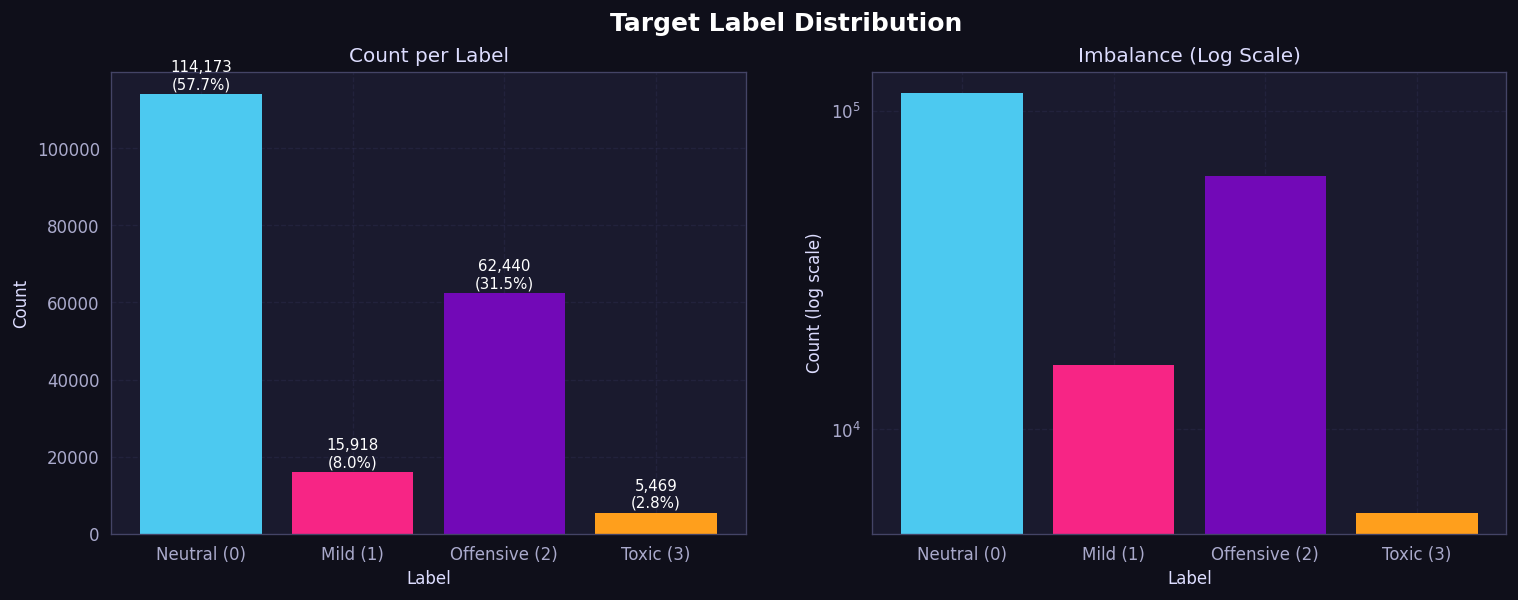

In [12]:
# Create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Main title for the whole figure
fig.suptitle('Target Label Distribution', fontsize=15, color='white', fontweight='bold')


# ---------- First plot: Raw counts ----------
ax = axes[0]

# Bar chart showing count of each label
bars = ax.bar(summary.index, summary['count'], color=PALETTE, edgecolor='none')

# Add text labels on top of each bar (count + percentage)
for bar, count, pct in zip(bars, summary['count'], summary['percentage']):
    ax.text(
        bar.get_x() + bar.get_width()/2,     # center of the bar
        bar.get_height() + 500,              # slightly above the bar
        f'{count:,}\n({pct:.1f}%)',          # formatted text (e.g., 12,345 (23.4%))
        ha='center',
        va='bottom',
        fontsize=9,
        color='white'
    )

# Axis labels and title
ax.set_xlabel('Label')
ax.set_ylabel('Count')
ax.set_title('Count per Label')

# Set x-axis ticks and map numeric labels → actual names
ax.set_xticks([0,1,2,3])
ax.set_xticklabels([LABEL_NAMES[i] for i in [0, 1, 2, 3]])


# ---------- Second plot: Log scale (to show imbalance clearly) ----------
ax = axes[1]

# Same bar chart again
bars = ax.bar(summary.index, summary['count'], color=PALETTE, edgecolor='none')

# Convert y-axis to logarithmic scale
ax.set_yscale('log')

# Labels and title
ax.set_xlabel('Label')
ax.set_ylabel('Count (log scale)')
ax.set_title('Imbalance (Log Scale)')

# Same x-axis labeling
ax.set_xticks([0,1,2,3])
ax.set_xticklabels([LABEL_NAMES[i] for i in [0, 1, 2, 3]])

### **<span style='color:#70cccc;'>4.2 Missing Value Analysis</span>**

#### **<span style='color:#70cccc;'>4.2.1 Missing Count and Percentage</span>**

In [13]:
# Count how many missing (NaN) values are present in each column
null_counts = train.isnull().sum()

# Compute percentage of missing values per column
# .mean() works because True = 1, False = 0 --> so it gives fraction of missing values
null_pct = (train.isnull().mean() * 100).round(2)

# Combine both count and percentage into a single DataFrame for easy viewing
missing_train = pd.DataFrame({
    'Missing Count': null_counts,
    'Missing %': null_pct
})

# Keep only columns that actually have missing values
missing_train = missing_train[missing_train['Missing Count'] > 0]

# Sort columns by highest number of missing values (most problematic first)
missing_train = missing_train.sort_values('Missing Count', ascending=False)

# Display the final table (nice formatted output in notebook)
display(missing_train)

,Missing Count,Missing %
race,145423,73.45
religion,145423,73.45
gender,145423,73.45
comment,1,0.00


#### **<span style='color:#70cccc;'>4.2.2 Missing Demographics Co-occurrence</span>**

In [14]:
# Create boolean masks: True where value is missing
race_nulls = train['race'].isnull()
religion_nulls = train['religion'].isnull()
gender_nulls = train['gender'].isnull()


# Count rows where ALL three fields are missing at the same time
print(f'\nAll three (race, religion, gender) simultaneously null: {(race_nulls & religion_nulls & gender_nulls).sum():,}')


# Count rows where ONLY race is missing but religion is NOT missing
print(f'Only race null but not religion: {(race_nulls & ~religion_nulls).sum()}')


All three (race, religion, gender) simultaneously null: 145,423
Only race null but not others: 0


- Missing values in race/religion/gender are perfectly co-occurring (same 145,423 rows)

#### **<span style='color:#70cccc;'>4.2.3 Missing Value Visualization</span>**

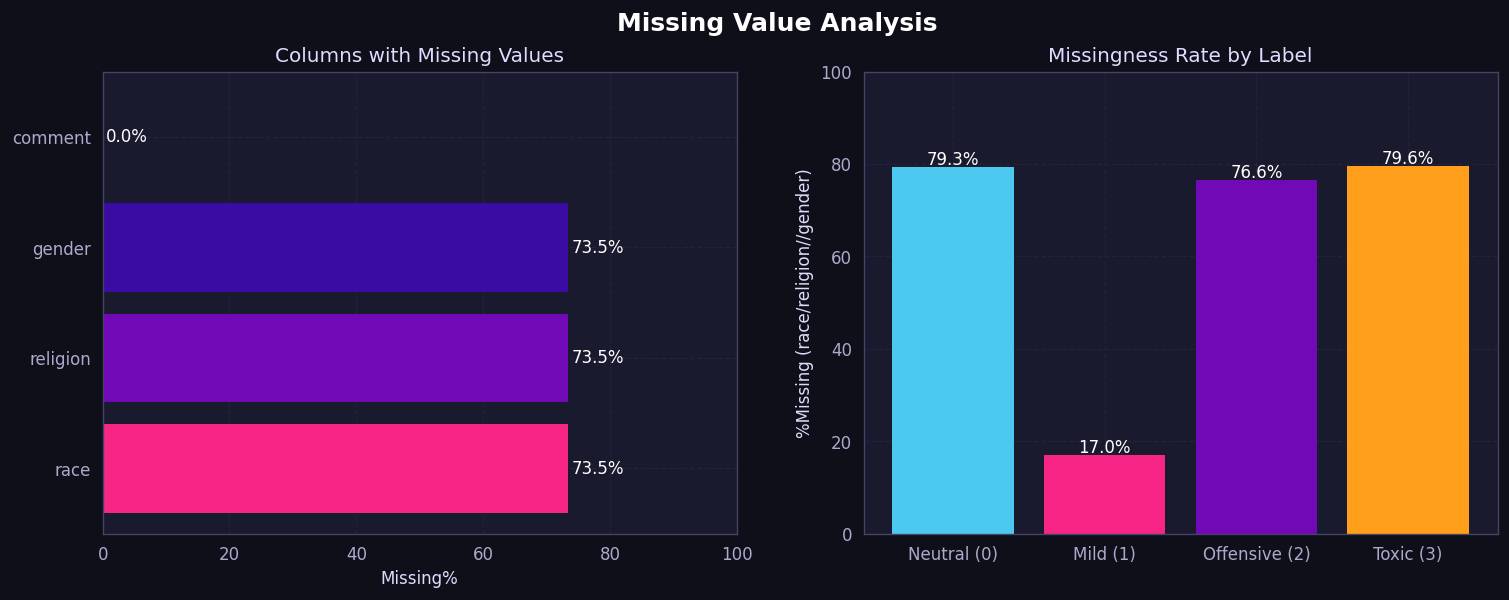

In [15]:
# Create 2 side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(15,5))

# Title for the whole figure
fig.suptitle('Missing Value Analysis', fontsize=15, color='white', fontweight='bold')


# ---------- LEFT PLOT: Missing % per column ----------
ax = axes[0]

# Get list of columns that actually have missing values
cols_with_missing = missing_train.index.tolist()

# Horizontal bar chart showing % missing for each column
ax.barh(
    cols_with_missing,
    missing_train['Missing %'],
    edgecolor='none',
    color=['#f72585', '#7209b7', '#3a0ca3', '#4cc9f0'][:len(cols_with_missing)]  # limit colors to number of columns
)

# Add percentage labels next to each bar
for i, v in enumerate(missing_train['Missing %']):
    ax.text(
        v + 0.5,   # slightly to the right of the bar
        i,         # vertical position
        f'{v:.1f}%',
        va='center',
        fontsize=10,
        color='white'
    )

# Axis labels and limits
ax.set_xlabel('Missing%')
ax.set_title('Columns with Missing Values')
ax.set_xlim(0,100)


# ---------- RIGHT PLOT: Missingness vs label ----------
ax = axes[1]

# Compute % of missing values in 'race' for each label
miss_by_label = train.groupby('label')['race'].apply(
    lambda x: x.isnull().mean() * 100
)

# Bar chart: how missingness varies across labels
ax.bar(
    miss_by_label.index,
    miss_by_label.values,
    color=PALETTE,
    edgecolor='none'
)

# Map numeric labels to names
ax.set_xticks([0,1,2,3])
ax.set_xticklabels([LABEL_NAMES[i] for i in [0, 1, 2, 3]])

# Add percentage labels above bars
for i, v in enumerate(miss_by_label.values):
    ax.text(
        i,
        v + 0.5,
        f'{v:.1f}%',
        ha='center',
        fontsize=10,
        color='white'
    )

# Axis labels and limits
ax.set_ylabel('%Missing (race/religion//gender)')
ax.set_title('Missingness Rate by Label')
ax.set_ylim(0,100)

### **<span style='color:#70cccc;'>4.3 Numerical Features Statistics</span>**

#### **<span style='color:#70cccc;'>4.3.1 Custom Descriptive Statistics</span>**

In [16]:
# List of numerical columns we want to analyze
num_cols = ['emoticon_1','emoticon_2','emoticon_3','upvote', 'downvote', 'if_1', 'if_2']

# Create an empty DataFrame where rows = columns, and we’ll fill stats as columns
stats_table = pd.DataFrame(index=num_cols)

# Loop through each numerical column
for col in num_cols:
    
    s = train[col]  # shorthand for current column
    
    # Basic central tendency
    stats_table.loc[col, 'mean'] = s.mean()
    stats_table.loc[col, 'median'] = s.median()
    
    # Spread / dispersion
    stats_table.loc[col, 'std'] = s.std()
    stats_table.loc[col, 'variance'] = s.var()
    
    # Range
    stats_table.loc[col, 'min'] = s.min()
    stats_table.loc[col, 'max'] = s.max()
    
    # Quartiles
    stats_table.loc[col, 'Q1'] = s.quantile(0.25)
    stats_table.loc[col, 'Q3'] = s.quantile(0.75)
    
    # Interquartile range (spread of middle 50%)
    stats_table.loc[col, 'IQR'] = s.quantile(0.75) - s.quantile(0.25)
    
    # Shape of distribution
    stats_table.loc[col, 'skewness'] = s.skew()      # asymmetry
    stats_table.loc[col, 'kurtosis'] = s.kurtosis()  # tail heaviness / outliers
    
    # Percentage of zeros (very useful for sparse-like features)
    stats_table.loc[col, 'zeros_%'] = (s == 0).mean() * 100


print('Custom Descriptive Statistics of Numerican Features:\n')

# Round values to 3 decimal places for clean display
display(stats_table.round(3))

Custom Descriptive Statistics of Numerican Features:



,mean,median,std,variance,min,max,Q1,Q3,IQR,skewness,kurtosis,zeros_%
emoticon_1,0.280,0.0,1.023,1.047,0.0,47.0,0.0,0.0,0.0,9.980,201.319,85.393
emoticon_2,0.048,0.0,0.258,0.067,0.0,11.0,0.0,0.0,0.0,7.557,93.135,95.905
emoticon_3,0.121,0.0,0.481,0.231,0.0,17.0,0.0,0.0,0.0,7.060,87.218,91.331
upvote,2.608,1.0,5.055,25.551,0.0,201.0,0.0,3.0,3.0,7.103,111.180,39.985
downvote,0.666,0.0,2.044,4.179,0.0,107.0,0.0,1.0,1.0,10.062,219.682,74.564
if_1,1.906,0.0,25.636,657.192,0.0,1860.0,0.0,4.0,4.0,63.702,4158.635,73.446
if_2,7.956,6.0,14.839,220.210,3.0,1833.0,4.0,10.0,6.0,67.321,6872.758,0.000


- Most of the numerical features are highly skewed, contain many zeros, and show heavy-tailed distributions with significant outliers.
- The emoticon features are extremely sparse, with over 85–95% zero values. The median and quartiles are all zero, indicating that most samples do not contain these features.

#### **<span style='color:#70cccc;'>4.3.2 Distributions (LogScale)</span>**

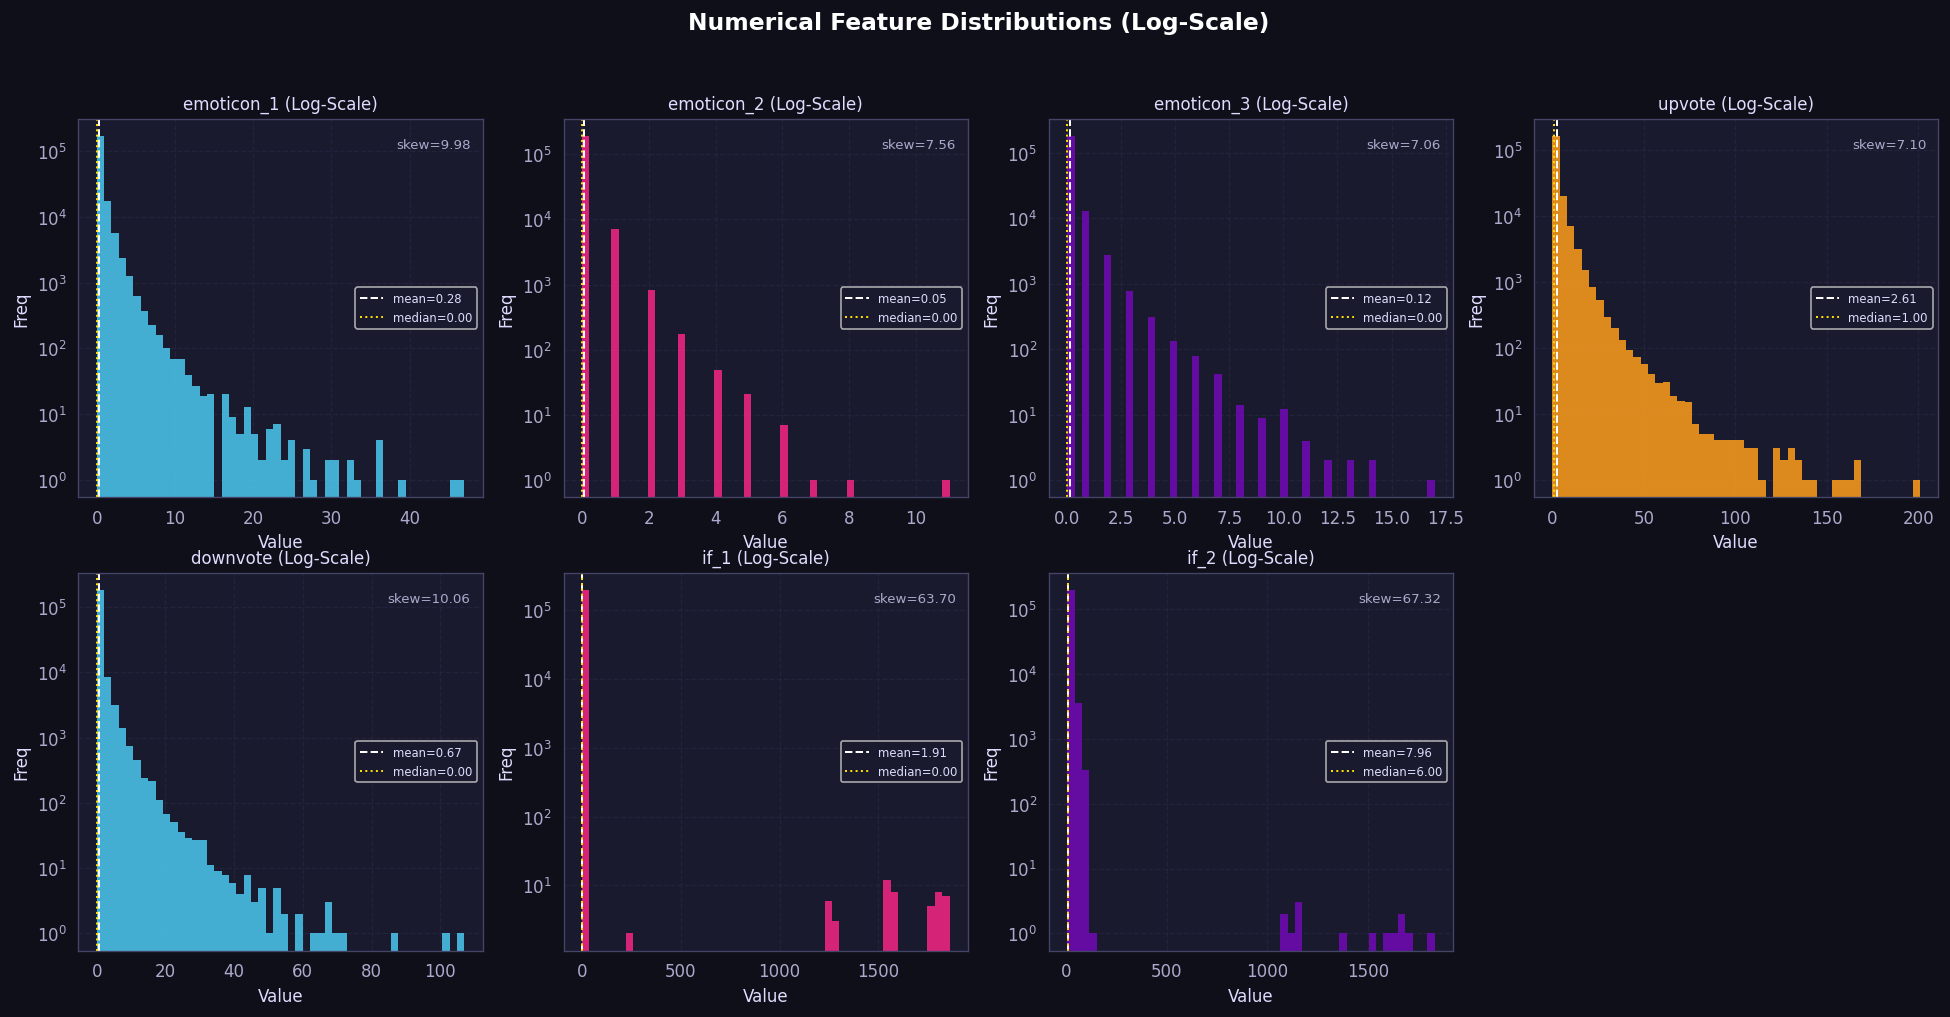

In [17]:
# Create a grid of 2 rows x 4 columns for subplots
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

# Flatten so we can loop over axes easily like a list
axes = axes.flatten()

# Overall title for all plots
fig.suptitle('Numerical Feature Distributions (Log-Scale)', fontsize=14, color='white', fontweight='bold')


# Loop through each numerical column
for i, col in enumerate(num_cols):
    
    ax = axes[i]          # pick the subplot
    data = train[col]     # current feature
    
    # Use log scale on y-axis to make small frequencies visible
    ax.set_yscale('log')
    
    # Plot histogram
    ax.hist(
        data,
        bins=50,
        color=PALETTE[i % 4],   # rotate colors
        edgecolor='none',
        alpha=0.85
    )
    
    # Draw vertical line for mean
    ax.axvline(
        data.mean(),
        color='white',
        linestyle='--',
        linewidth=1.2,
        label=f'mean={data.mean():.2f}'
    )
    
    # Draw vertical line for median
    ax.axvline(
        data.median(),
        color='#ffdd00',
        linestyle=':',
        linewidth=1.2,
        label=f'median={data.median():.2f}'
    )
    
    # Titles and labels
    ax.set_title(f"{col} (Log-Scale)", fontsize=10)
    ax.set_xlabel('Value')
    ax.set_ylabel('Freq')
    
    # Show legend (mean vs median)
    ax.legend(fontsize=7)
    
    # Compute skewness and display it inside the plot
    skw = skew(data)
    ax.text(
        0.97, 0.95,
        f'skew={skw:.2f}',
        transform=ax.transAxes,   # position relative to axes (not data)
        ha='right',
        va='top',
        fontsize=8,
        color='#aaaacc'
    )


# Hide the last empty subplot
axes[-1].set_visible(False)

#### **<span style='color:#70cccc;'>Empirical Cummulative Distribution Function</span>**

> proportion of data points less than or equal to a given value

#### **<span style='color:#70cccc;'>4.3.3 Upvotes ECDF</span>**

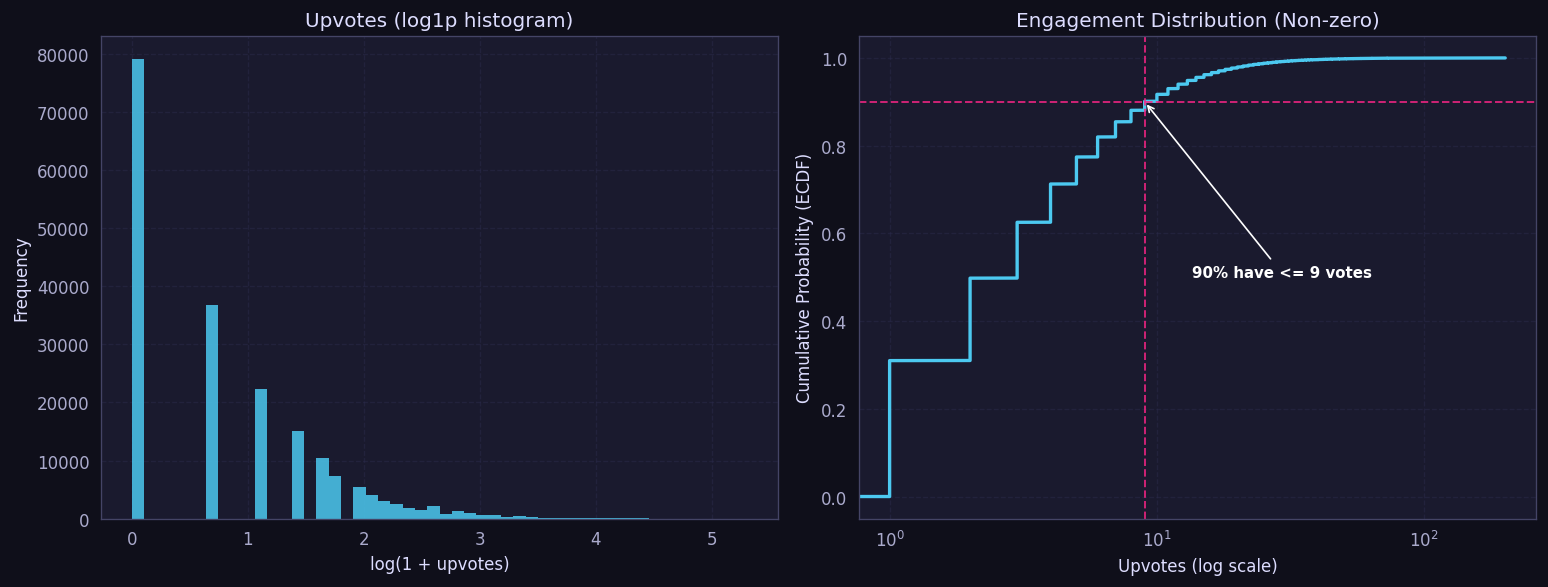

In [18]:
# ---------- Histogram (log-transformed) ----------
def plot_upvote_hist(data, ax):
    
    # Apply log(1 + x) transform to reduce skew
    # (handles zeros safely -> log(0+1)=0)
    data_t = np.log1p(data)
    
    # Plot histogram of transformed data
    ax.hist(
        data_t,
        bins=50,
        alpha=0.85,
        color='#4cc9f0',
        edgecolor='none'
    )
    
    # Labels and title
    ax.set_xlabel("log(1 + upvotes)")
    ax.set_ylabel("Frequency")
    ax.set_title("Upvotes (log1p histogram)")

# ---------- ECDF Plot ----------
def plot_upvote_ectrain(data, ax):
    
    # Remove zero values → focus on actual engagement
    nz_data = data[data > 0]
    
    # Compute empirical cumulative distribution function
    ecdf = ECDF(nz_data)
    
    # Plot ECDF curve
    ax.plot(ecdf.x, ecdf.y, linewidth=2, color='#4cc9f0')
    
    
    # ----- Highlight 90th percentile -----
    
    # Compute 90th percentile value
    p90_val = np.percentile(nz_data, 90)
    
    # Horizontal line at 90%
    ax.axhline(0.9, color='#f72585', linestyle='--', linewidth=1.2, alpha=0.8)
    
    # Vertical line at value corresponding to 90%
    ax.axvline(p90_val, color='#f72585', linestyle='--', linewidth=1.2, alpha=0.8)
    
    # Annotate the meaning of this point
    ax.annotate(
        f"90% have <= {int(p90_val)} votes",
        xy=(p90_val, 0.9),
        xytext=(p90_val * 1.5, 0.5),
        arrowprops=dict(arrowstyle="->", color='white'),
        color='white',
        fontsize=9,
        fontweight='bold'
    )
    
    # Log scale for x-axis (better visibility of wide range)
    ax.set_xscale('log')
    
    # Labels and title
    ax.set_xlabel("Upvotes (log scale)")
    ax.set_ylabel("Cumulative Probability (ECDF)")
    ax.set_title("Engagement Distribution (Non-zero)")


# ---------- Create plots ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: histogram (distribution shape)
plot_upvote_hist(train['upvote'], axes[0])

# Right: ECDF (cumulative behavior)
plot_upvote_ectrain(train['upvote'], axes[1])

# Adjust spacing
plt.tight_layout()

# Show plots
plt.show()

#### **<span style='color:#70cccc;'>4.3.4 Downvotes ECDF</span>**

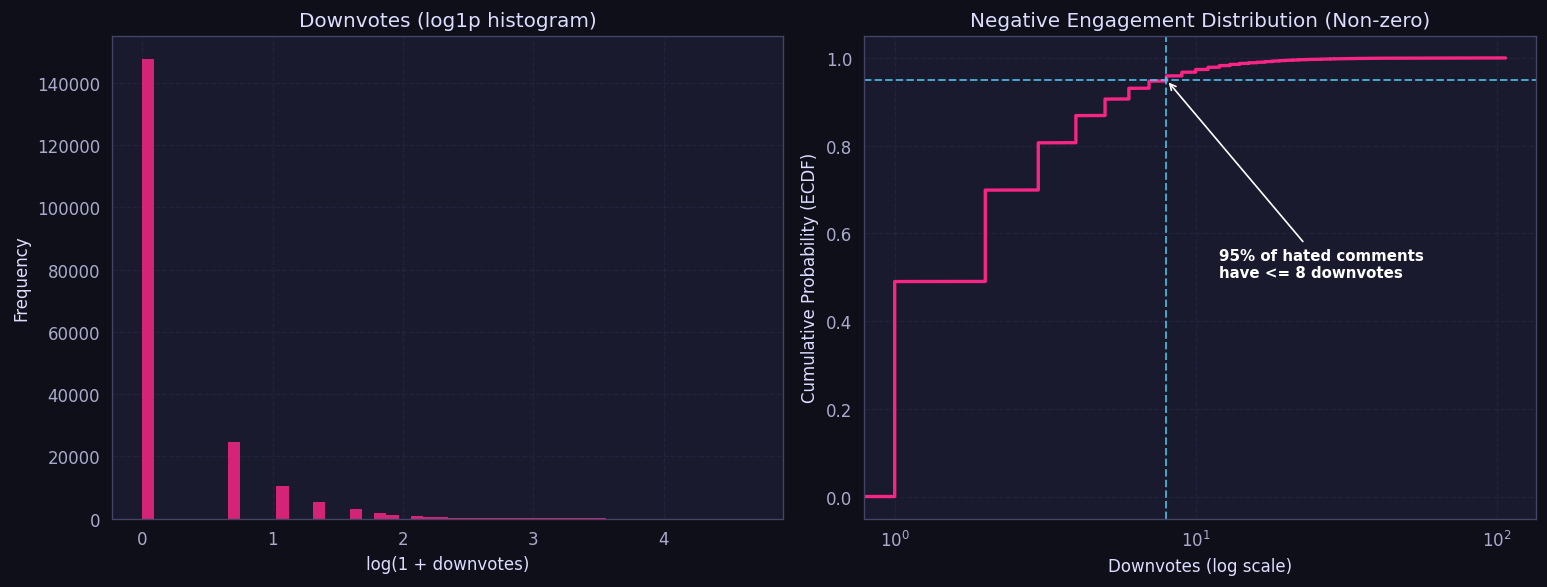

In [19]:
def plot_downvote_hist(data, ax):
    data_t = np.log1p(data)
    ax.hist(data_t, bins=50, alpha=0.85, color='#f72585', edgecolor='none')
    ax.set_xlabel("log(1 + downvotes)")
    ax.set_ylabel("Frequency")
    ax.set_title("Downvotes (log1p histogram)")

def plot_downvote_ectrain(data, ax):
    nz_data = data[data > 0]
    ecdf = ECDF(nz_data)
    ax.plot(ecdf.x, ecdf.y, linewidth=2, color='#f72585')
    
    # 95th Percentile Marker (Downvotes are more concentrated)
    p95_val = np.percentile(nz_data, 95)
    ax.axhline(0.95, color='#4cc9f0', linestyle='--', linewidth=1.2, alpha=0.8)
    ax.axvline(p95_val, color='#4cc9f0', linestyle='--', linewidth=1.2, alpha=0.8)
    ax.annotate(f"95% of hated comments\nhave <= {int(p95_val)} downvotes", 
                xy=(p90_val if "p90_val" in locals() else p95_val, 0.95), xytext=(p95_val*1.5, 0.5),
                arrowprops=dict(arrowstyle="->", color='white'),
                color='white', fontsize=9, fontweight='bold')
    
    ax.set_xscale('log')
    ax.set_xlabel("Downvotes (log scale)")
    ax.set_ylabel("Cumulative Probability (ECDF)")
    ax.set_title("Negative Engagement Distribution (Non-zero)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_downvote_hist(train['downvote'], axes[0])
plot_downvote_ectrain(train['downvote'], axes[1])
plt.tight_layout()
plt.show()

#### **<span style='color:#70cccc;'>4.3.5 Internal Features (IF1 & IF2) ECDF</span>**

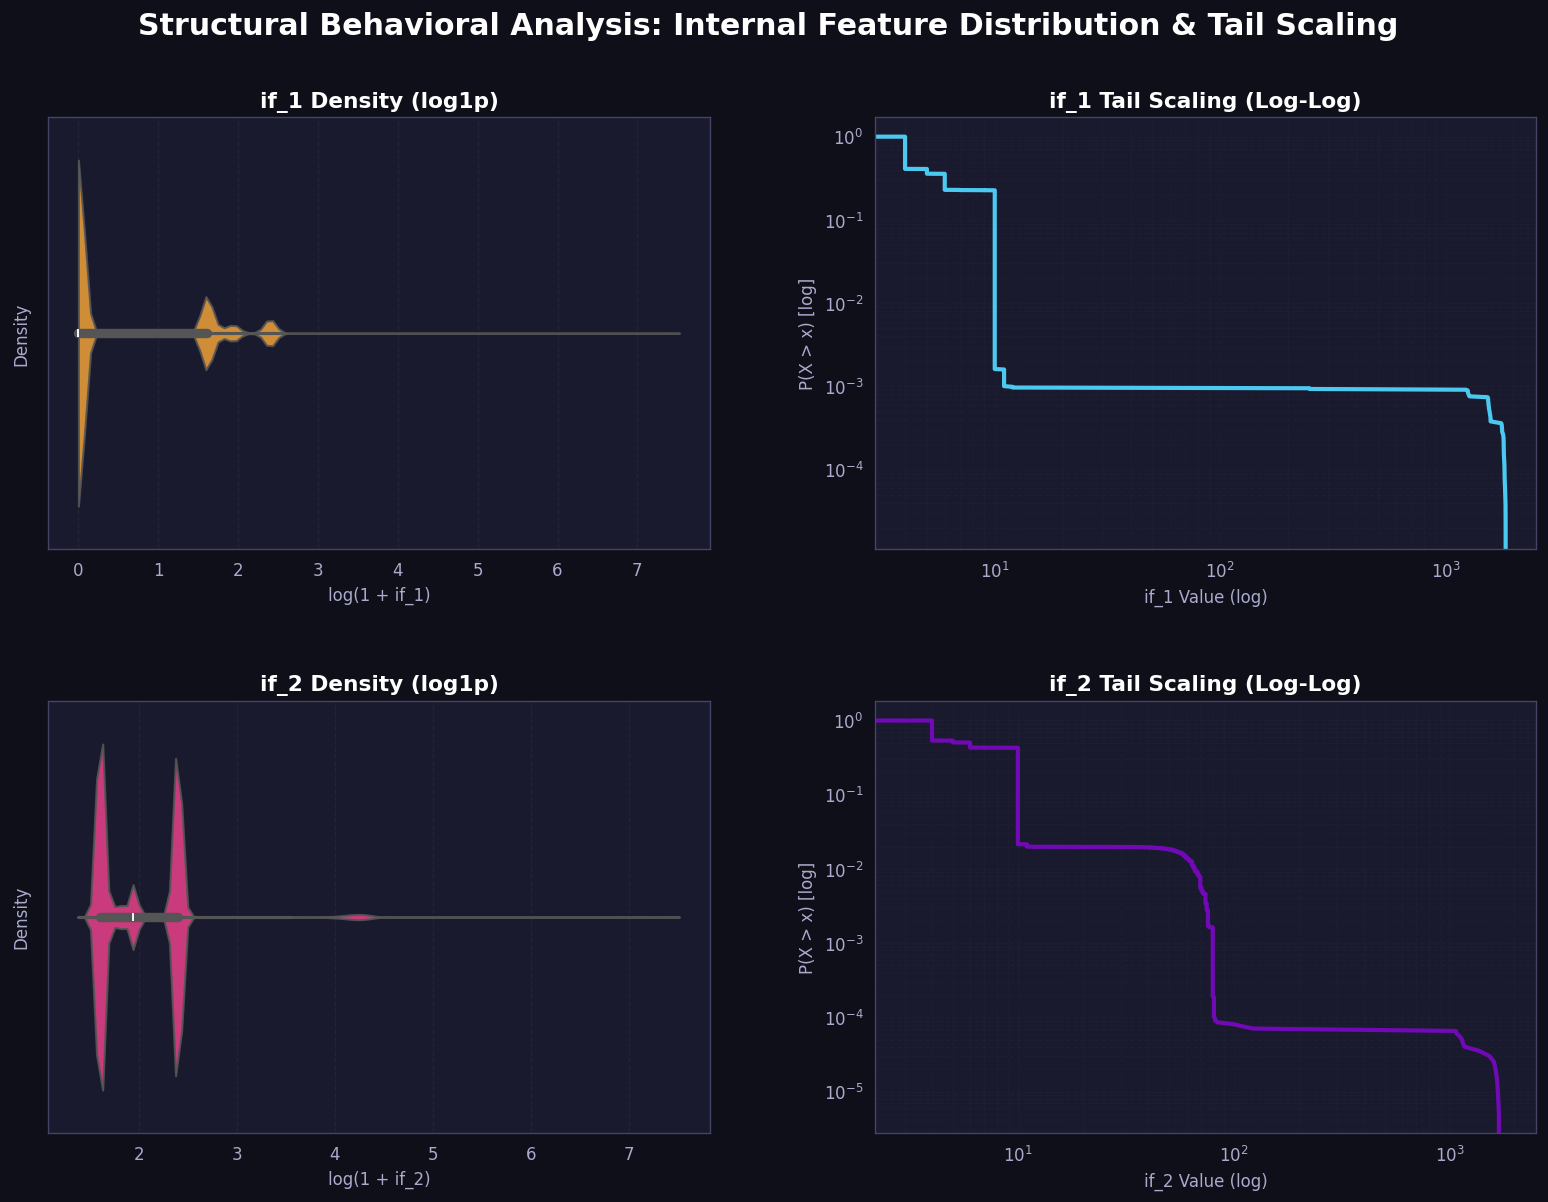

In [20]:
# ---------- Violin Plot (distribution shape) ----------
def plot_structural_violin(data, col, ax, color):
    
    # Apply log(1 + x) to compress extreme values and handle zeros
    data_t = np.log1p(data)
    
    # Violin plot shows full distribution (like a smooth histogram)
    sns.violinplot(
        x=data_t,
        ax=ax,
        color=color,
        cut=0,        # don't extend beyond data range
        alpha=0.9
    )
    
    # Titles and labels
    ax.set_title(f"{col} Density (log1p)", fontsize=13, color="white", fontweight="bold")
    ax.set_xlabel(f"log(1 + {col})", color="#aaaacc")
    ax.set_ylabel("Density", color="#aaaacc")

# ---------- ECDF Tail (Survival Function) ----------
def plot_structural_ecdf(data, col, ax, color):
    
    # Remove zeros → focus on meaningful signal
    nz = data[data > 0]
    
    # If no non-zero values exist, avoid crashing
    if len(nz) == 0: 
        ax.text(0.5, 0.5, "No Signal", color="white", ha="center")
        return

    # Compute ECDF
    ecdf = ECDF(nz)
    
    # Plot survival function: P(X > x)
    # (how many values exceed a given threshold)
    ax.plot(ecdf.x, 1 - ecdf.y, linewidth=2.5, color=color)
    
    # Log-log scale to analyze tail behavior
    ax.set_xscale("log")
    ax.set_yscale("log")
    
    # Titles and labels
    ax.set_title(f"{col} Tail Scaling (Log-Log)", fontsize=13, color="white", fontweight="bold")
    ax.set_xlabel(f"{col} Value (log)", color="#aaaacc")
    ax.set_ylabel("P(X > x) [log]", color="#aaaacc")
    
    # Grid for better readability on log scale
    ax.grid(True, which="both", ls="--", alpha=0.2)


# ---------- Create 2x2 layout ----------
fig, axes = plt.subplots(2, 2, figsize=(16, 11), facecolor="#0f0f1a")

# Adjust spacing between plots
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# First feature: if_1
plot_structural_violin(train["if_1"], "if_1", axes[0, 0], "#ff9f1c")
plot_structural_ecdf(train["if_1"], "if_1", axes[0, 1], "#4cc9f0")

# Second feature: if_2
plot_structural_violin(train["if_2"], "if_2", axes[1, 0], "#f72585")
plot_structural_ecdf(train["if_2"], "if_2", axes[1, 1], "#7209b7")

# Main title
plt.suptitle(
    "Structural Behavioral Analysis: Internal Feature Distribution & Tail Scaling", 
    fontsize=18,
    color="white",
    fontweight="bold",
    y=0.96
)

plt.show()

#### **<span style='color:#70cccc;'>4.3.6 Kruskal-Wallis Testing: Do these numerical features predict Toxicity?</span>**

Kruskal-Wallis significance: *** p<0.001  ** p<0.01  * p<0.05  ns=not significant


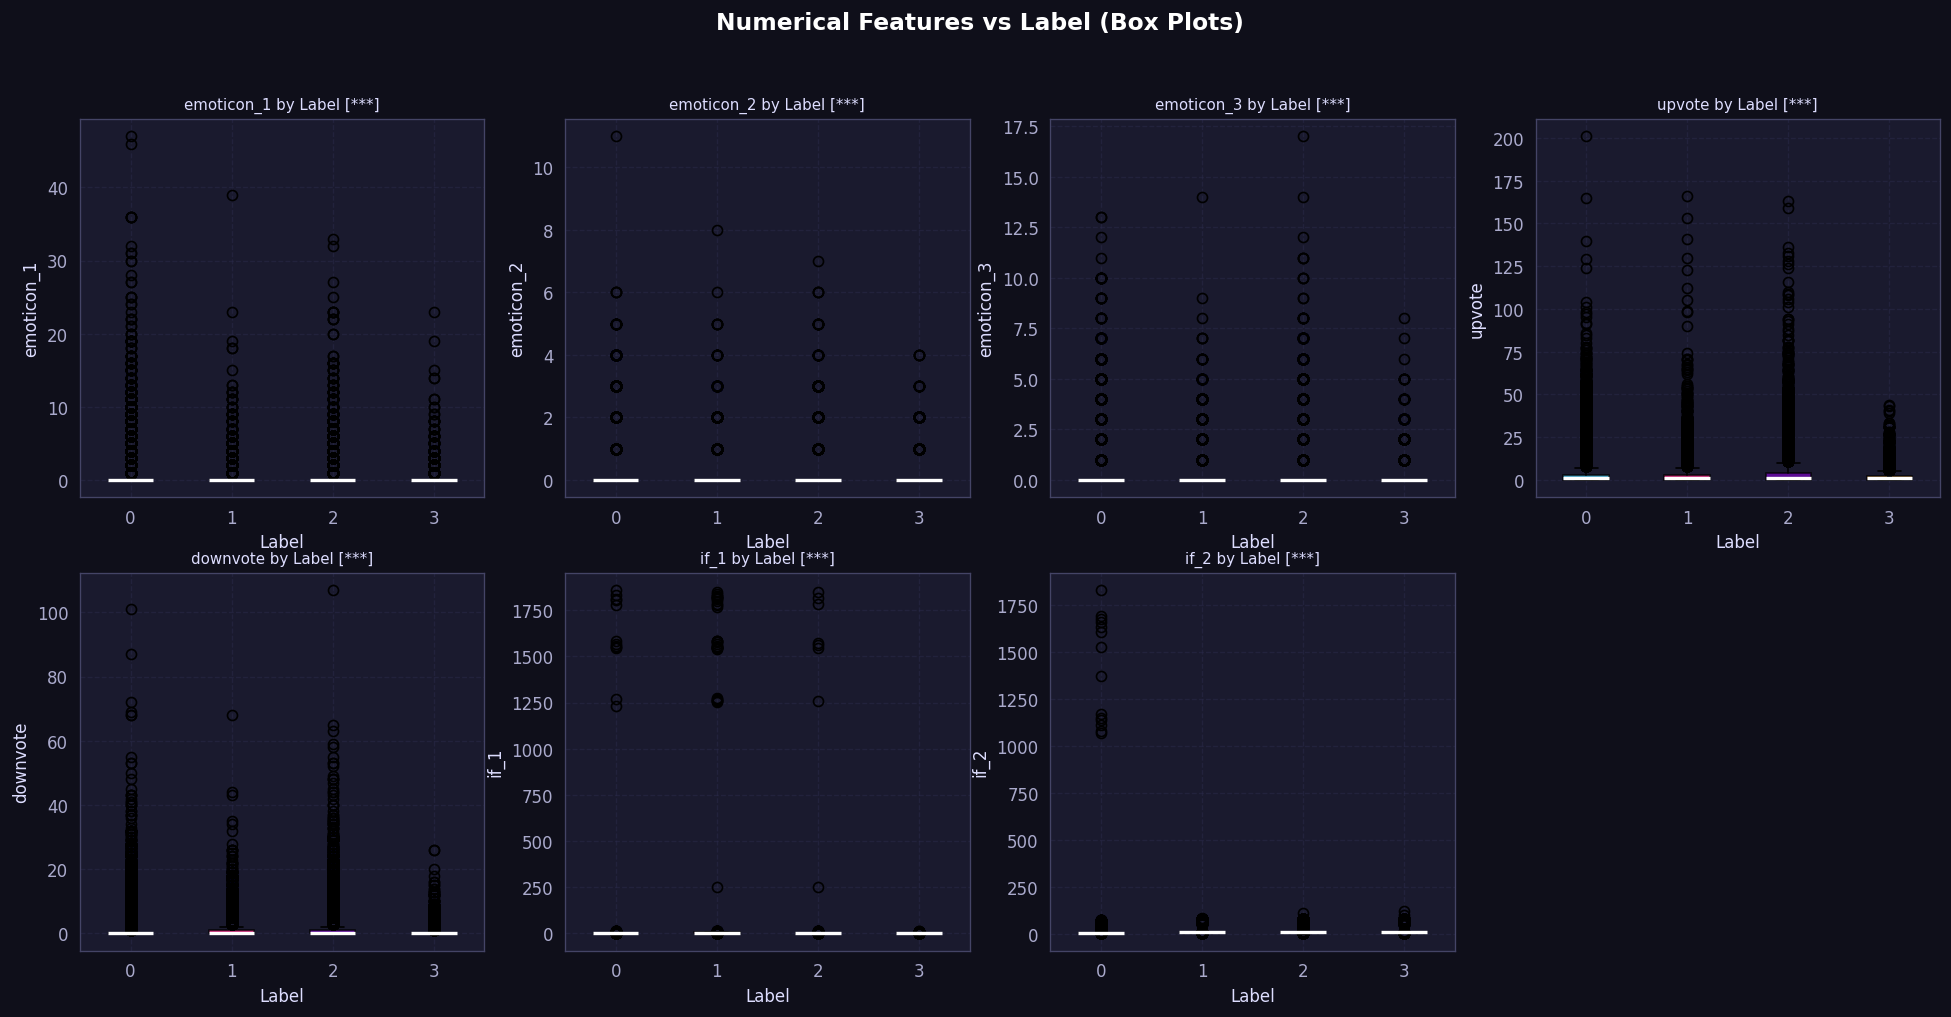

In [21]:
# Create 2x4 grid of plots
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

# Overall title
fig.suptitle('Numerical Features vs Label (Box Plots)', fontsize=14, color='white', fontweight='bold')

# Loop through each numerical feature
for i, col in enumerate(num_cols):
    
    ax = axes[i]
    
    # Split data by label (0,1,2,3)
    data_by_label = [
        train[train['label'] == lbl][col].values 
        for lbl in sorted(train['label'].unique())
    ]
    
    # Create boxplot for each label
    bp = ax.boxplot(
        data_by_label,
        patch_artist=True,   # allows coloring boxes
        notch=False,
        medianprops=dict(color='white', linewidth=2)
    )
    
    # Color each box
    for patch, color in zip(bp['boxes'], PALETTE):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    
    # Label x-axis with class labels
    ax.set_xticklabels([str(l) for l in sorted(train['label'].unique())])
    ax.set_xlabel('Label')
    ax.set_ylabel(col)
    
    # Basic title
    ax.set_title(f'{col} by Label', fontsize=9)

    # ---------- Statistical test ----------
    
    # Perform Kruskal-Wallis test (non-parametric ANOVA)
    stat, p = kruskal(*data_by_label)
    
    # Convert p-value --> significance level
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    
    # Update title with significance
    ax.set_title(f'{col} by Label [{sig}]', fontsize=9)

# Hide last empty subplot
axes[-1].set_visible(False)

# Legend for significance symbols
print('Kruskal-Wallis significance: *** p<0.001  ** p<0.01  * p<0.05  ns=not significant')

### **<span style='color:#70cccc;'>4.4 Categorical Feature Analysis</span>**

#### **<span style='color:#70cccc;'>4.4.1 Demographic Distributions</span>**

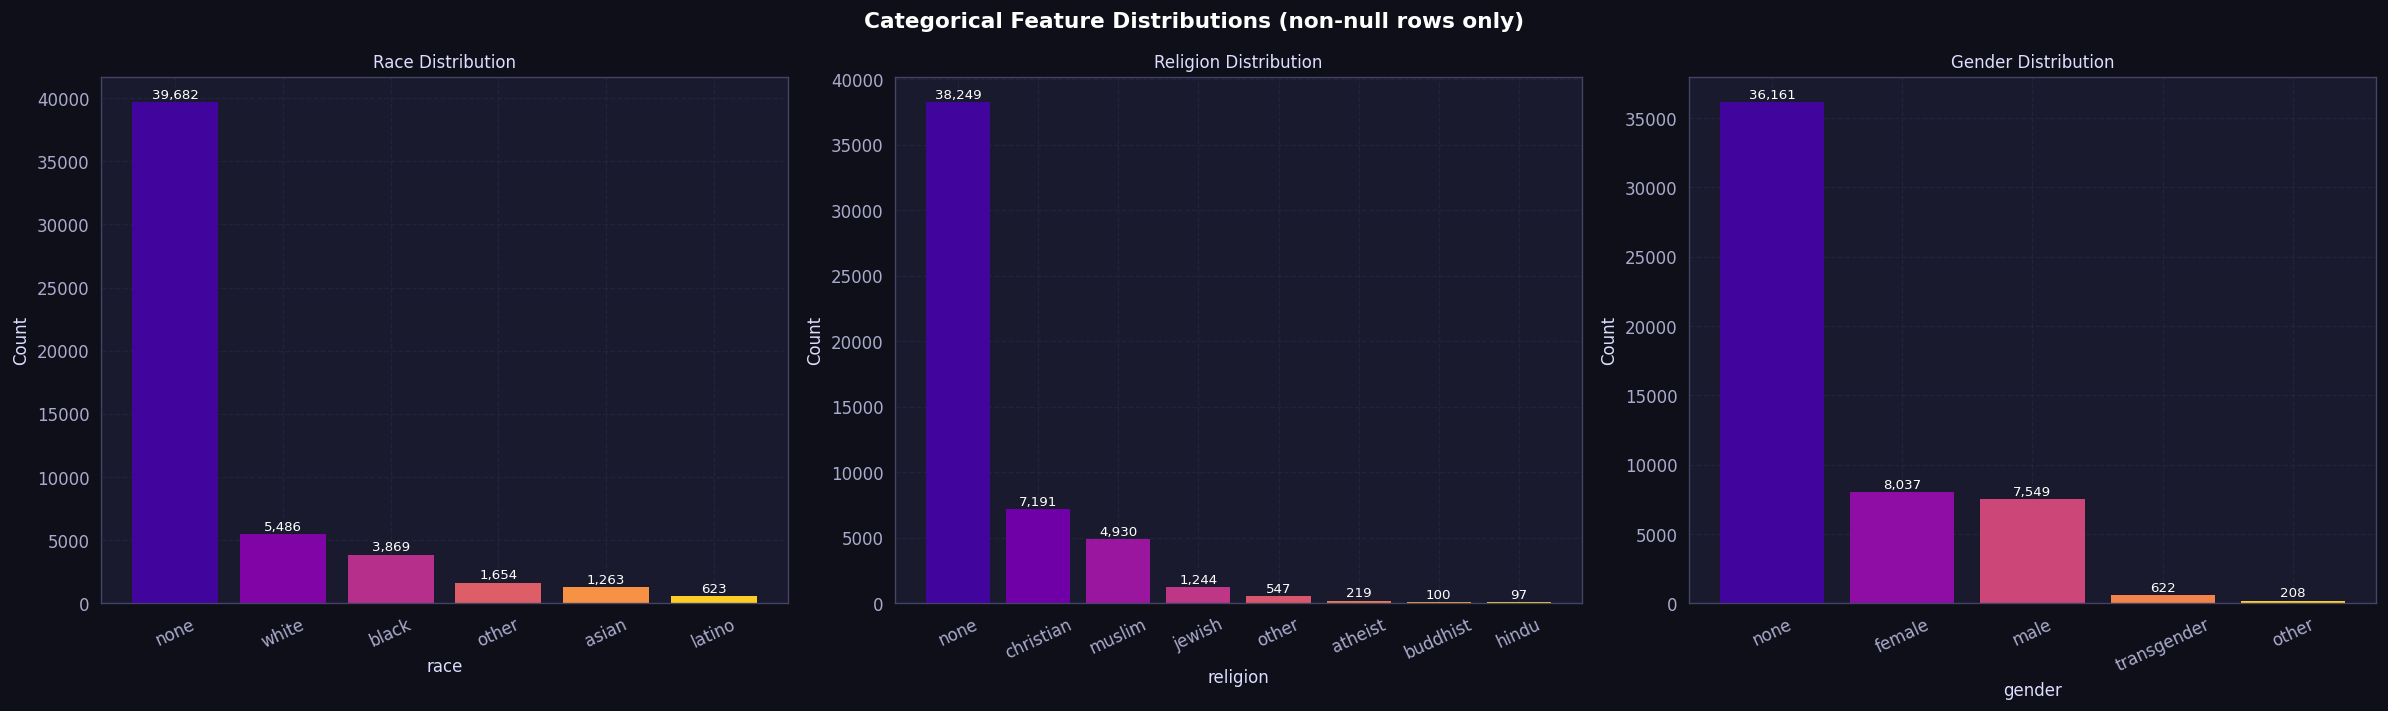

In [22]:
# Categorical columns to analyze
cat_cols = ['race', 'religion', 'gender']

# Create 3 side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Main title
fig.suptitle('Categorical Feature Distributions (non-null rows only)', fontsize=13, color='white', fontweight='bold')


# Loop over each column and its subplot
for ax, col in zip(axes, cat_cols):
    
    # Count frequency of each category (NaNs automatically ignored)
    vc = train[col].value_counts()
    
    # Generate color gradient (just for nicer visuals)
    colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(vc)))
    
    # Bar chart of category counts
    bars = ax.bar(vc.index, vc.values, color=colors, edgecolor='none')
    
    # Add count labels above each bar
    for bar, v in zip(bars, vc.values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 50,
            f'{v:,}',            # formatted with commas
            ha='center',
            va='bottom',
            fontsize=8,
            color='white'
        )
    
    # Titles and labels
    ax.set_title(f'{col.capitalize()} Distribution', fontsize=10)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    
    # Rotate x labels so they don’t overlap
    ax.tick_params(axis='x', rotation=25)

# Adjust layout and display
plt.tight_layout()
plt.show()

#### **<span style='color:#70cccc;'>4.4.2 Chi2 Test for Target Variable Dependency on Categorical Features</span>**

In [23]:
train['race_filled']     = train['race'].fillna('none')
train['religion_filled'] = train['religion'].fillna('none')
train['gender_filled']   = train['gender'].fillna('none')

print('==== Chi-Square Tests: Categorical Feature vs Label ====')
for col in ['race_filled', 'religion_filled', 'gender_filled', 'disability']:
    ct = pd.crosstab(train[col], train['label'])
    chi2, p, dof, expected = chi2_contingency(ct)
    
    # Cramér's V
    n = ct.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    print(f'{col:20s}  χ²={chi2:.1f}  dof={dof}  p={p:.2e}  {sig}  Cramér\'s V={cramers_v:.4f}')

print('\nCramér\'s V: 0–0.1=negligible, 0.1–0.3=small, 0.3–0.5=moderate, >0.5=large')

==== Chi-Square Tests: Categorical Feature vs Label ====
race_filled           χ²=45429.2  dof=15  p=0.00e+00  ***  Cramér's V=0.2766
religion_filled       χ²=32056.8  dof=21  p=0.00e+00  ***  Cramér's V=0.2323
gender_filled         χ²=10202.0  dof=12  p=0.00e+00  ***  Cramér's V=0.1311
disability            χ²=857.6  dof=3  p=1.42e-185  ***  Cramér's V=0.0658

Cramér's V: 0–0.1=negligible, 0.1–0.3=small, 0.3–0.5=moderate, >0.5=large


#### **<span style='color:#70cccc;'>4.4.3 Stacked Bar: Label Distribution within Demographic Category </span>**

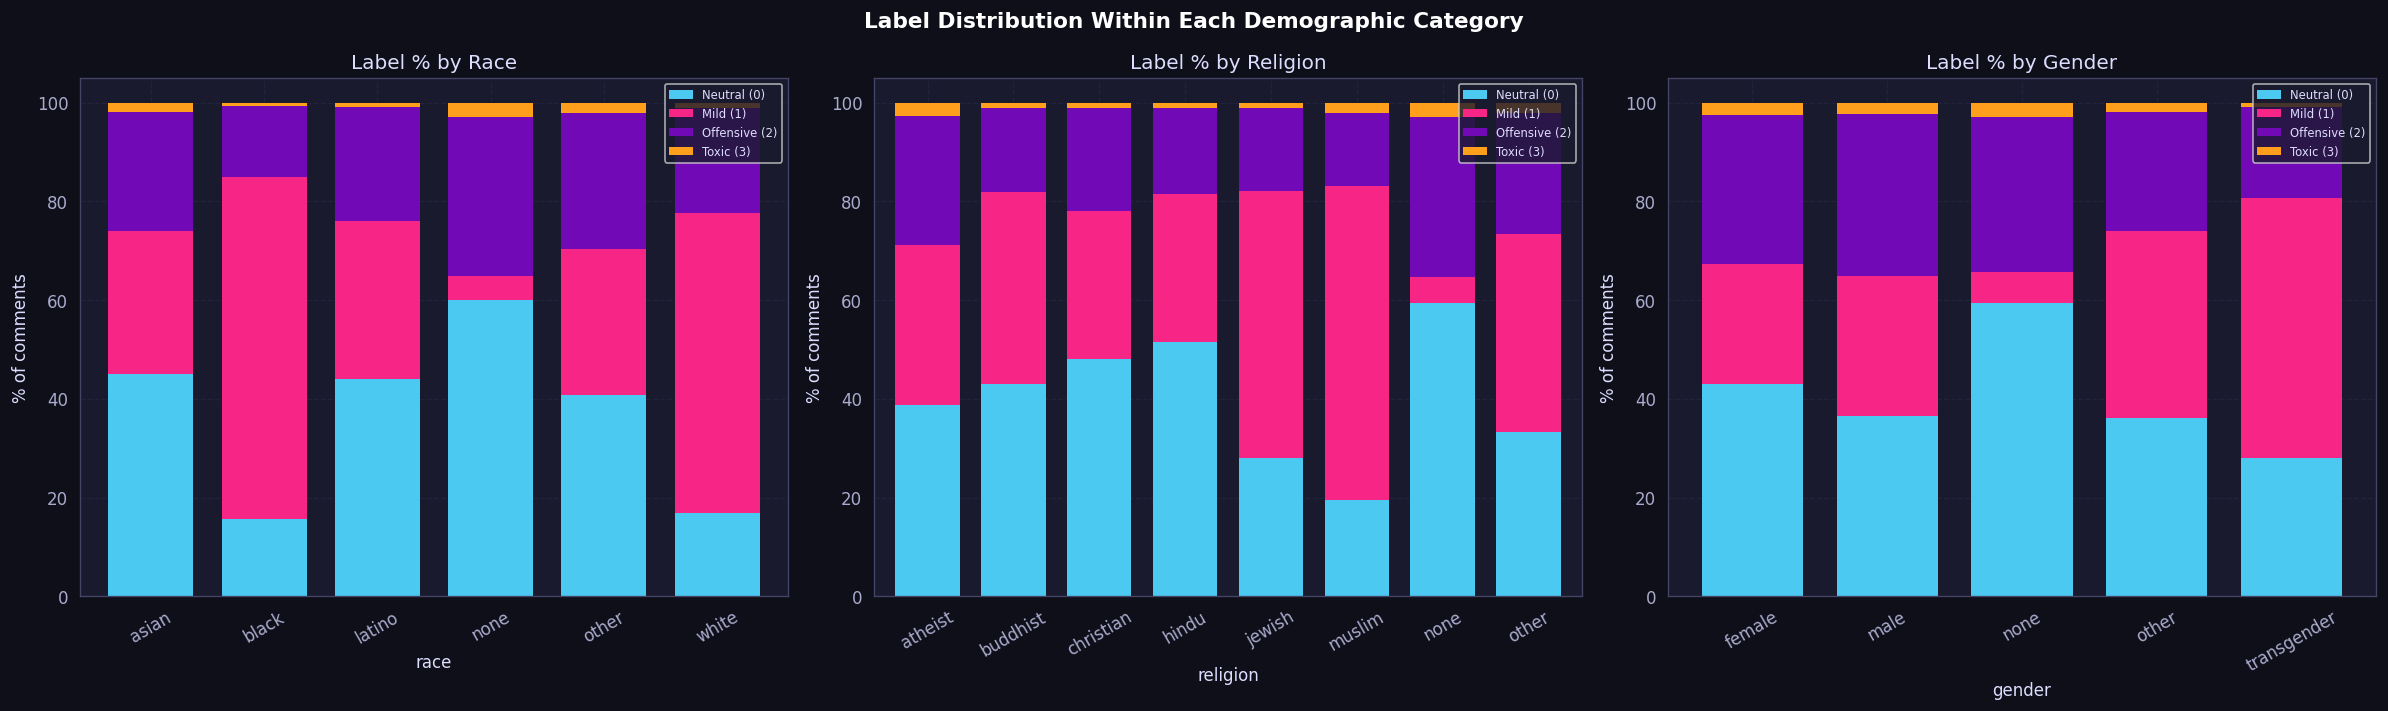

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Label Distribution Within Each Demographic Category', fontsize=13, color='white', fontweight='bold')

for ax, col in zip(axes, ['race_filled', 'religion_filled', 'gender_filled']):
    ct = pd.crosstab(train[col], train['label'], normalize='index') * 100
    ct.plot(kind='bar', stacked=True, ax=ax, color=PALETTE, edgecolor='none', width=0.75)
    ax.set_xlabel(col.replace('_filled', '')); ax.set_ylabel('% of comments')
    ax.set_title(f'Label % by {col.replace("_filled", "").capitalize()}')
    ax.legend([LABEL_NAMES[i] for i in range(4)], fontsize=7, loc='upper right')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout(); plt.show()

### **<span style='color:#70cccc;'>4.5 Text Feature Analysis</span>**

#### **<span style='color:#70cccc;'>4.5.1 WordCloud Visualization Across Labels</span>**

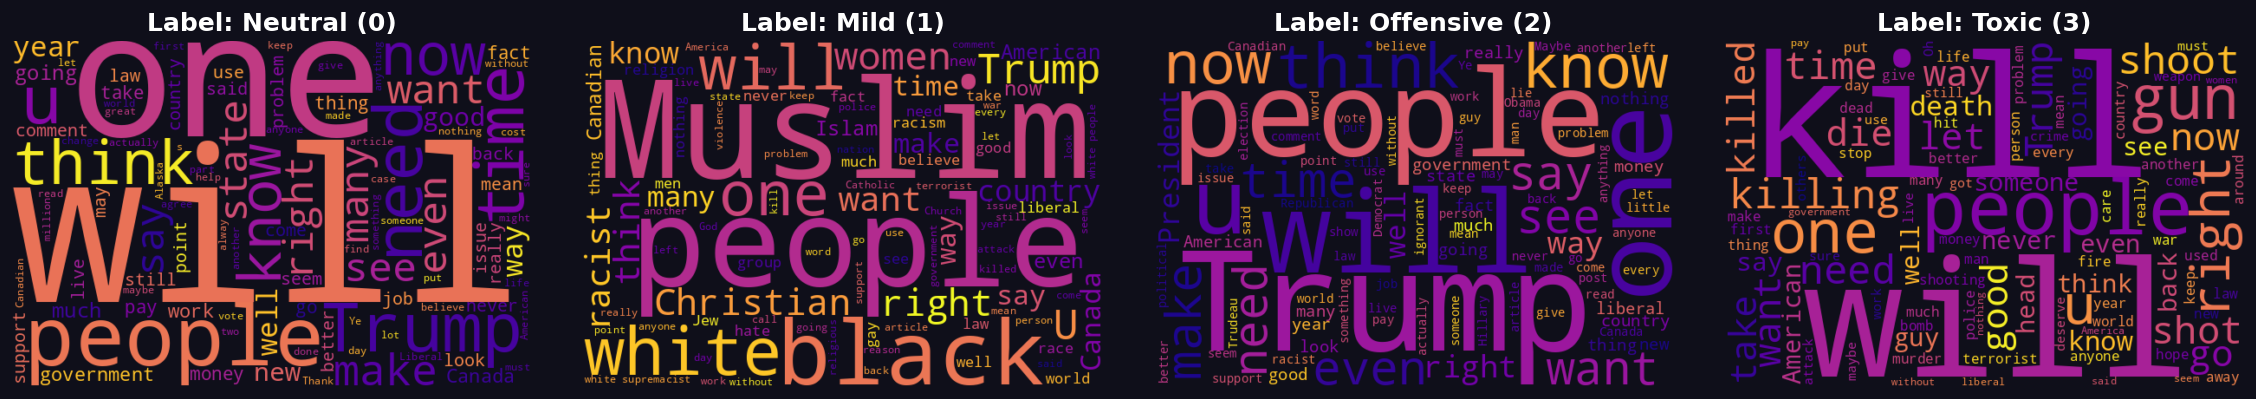

In [25]:
def plot_wordclouds(df, text_col='comment', label_col='label'):
    labels = sorted(df[label_col].unique())
    
    fig, axes = plt.subplots(1, 4, figsize=(24, 6), facecolor="#0f0f1a")
    plt.subplots_adjust(wspace=0.1)

    for i, label in enumerate(labels):
        text = " ".join(df[df[label_col] == label][text_col].astype(str).tolist())
        
        if not text.strip():
             axes[i].text(0.5, 0.5, "No text available", color="white", ha="center")
             continue
             
        wc = WordCloud(
            width=600, height=400, 
            background_color="#0f0f1a", 
            max_words=100, 
            colormap="plasma", 
            contour_width=2, 
            contour_color="#4cc9f0" 
        ).generate(text)
        
        axes[i].imshow(wc, interpolation="bilinear")
        axes[i].set_title(f"Label: {LABEL_NAMES.get(label, label)}", fontsize=15, color="white", fontweight="bold")
        axes[i].axis("off")

    plt.show()

plot_wordclouds(train.sample(50000))

#### **<span style='color:#70cccc;'>4.5.2 Text Statistics (Overall)</span>**

In [26]:
train['comment_clean'] = train['comment'].fillna('')
train['char_len']      = train['comment_clean'].str.len()
train['word_count']    = train['comment_clean'].str.split().str.len()
train['sentence_count']= train['comment_clean'].str.count(r'[.!?]+') + 1
train['avg_word_len']  = train['comment_clean'].apply(
    lambda t: np.mean([len(w) for w in t.split()]) if t.split() else 0
)
train['unique_words']  = train['comment_clean'].apply(lambda t: len(set(t.lower().split())))
train['lexical_diversity'] = train.apply(
    lambda r: r['unique_words'] / r['word_count'] if r['word_count'] > 0 else 0, axis=1
)
train['exclamation']   = train['comment_clean'].str.count('!')
train['question']      = train['comment_clean'].str.count(r'\?')
train['uppercase_ratio'] = train['comment_clean'].apply(
    lambda t: sum(1 for c in t if c.isupper()) / max(len(t), 1)
)

text_metrics = ['char_len', 'word_count', 'avg_word_len', 'sentence_count',
                'lexical_diversity', 'exclamation', 'question', 'uppercase_ratio']

text_stats = pd.DataFrame(index=text_metrics)
for m in text_metrics:
    s = train[m]
    text_stats.loc[m, 'mean']     = s.mean()
    text_stats.loc[m, 'median']   = s.median()
    text_stats.loc[m, 'std']      = s.std()
    text_stats.loc[m, 'min']      = s.min()
    text_stats.loc[m, 'max']      = s.max()
    text_stats.loc[m, 'skewness'] = skew(s.dropna())

print('==== Text Feature Statistics ====')
display(text_stats.round(3))

==== Text Feature Statistics ====


,mean,median,std,min,max,skewness
char_len,302.909,211.000,266.442,0.0,1892.0,1.226
word_count,52.397,37.000,45.770,0.0,315.0,1.231
avg_word_len,4.908,4.714,2.804,0.0,333.0,42.181
sentence_count,4.751,4.000,3.233,1.0,57.0,1.789
lexical_diversity,0.869,0.878,0.106,0.0,1.0,-0.425
exclamation,0.224,0.000,0.952,0.0,96.0,23.076
question,0.440,0.000,0.992,0.0,49.0,5.653
uppercase_ratio,0.036,0.027,0.043,0.0,1.0,9.883


#### **<span style='color:#70cccc;'>4.5.3 Text Statistics (Label-wise)</span>**

In [27]:
text_by_label = train.groupby('label')[text_metrics].agg(['mean', 'median', 'std'])
print('==== Text Statistics by Label ====')
display(text_by_label.T.round(3))

==== Text Statistics by Label ====


label                           0        1        2        3
char_len          mean    295.897  335.710  316.893  194.172
                  median  199.000  246.000  232.000  128.000
                  std     269.586  267.544  262.830  194.253
word_count        mean     51.187   57.233   54.902   34.978
                  median   35.000   42.000   40.000   24.000
                  std      46.289   45.506   45.303   34.361
avg_word_len      mean      4.962    4.933    4.835    4.561
                  median    4.700    4.818    4.734    4.500
                  std       3.567    1.232    1.096    0.747
sentence_count    mean      4.638    5.006    4.977    3.772
                  median    4.000    4.000    4.000    3.000
                  std       3.207    3.261    3.294    2.639
lexical_diversity mean      0.871    0.854    0.865    0.904
                  median    0.882    0.860    0.872    0.923
                  std       0.108    0.106    0.102    0.096
exclamation       mean      0.198    0.196    0.275    0.260
                  median    0.000    0.000    0.000    0.000
                  std       0.860    0.796    1.135    0.893
question          mean      0.425    0.544    0.450    0.336
                  median    0.000    0.000    0.000    0.000
                  std       0.948    1.098    1.054    0.798
uppercase_ratio   mean      0.036    0.035    0.034    0.037
                  median    0.027    0.028    0.027    0.026
                  std       0.044    0.042    0.040    0.049

#### **<span style='color:#70cccc;'>4.5.4 Text Distribution</span>**

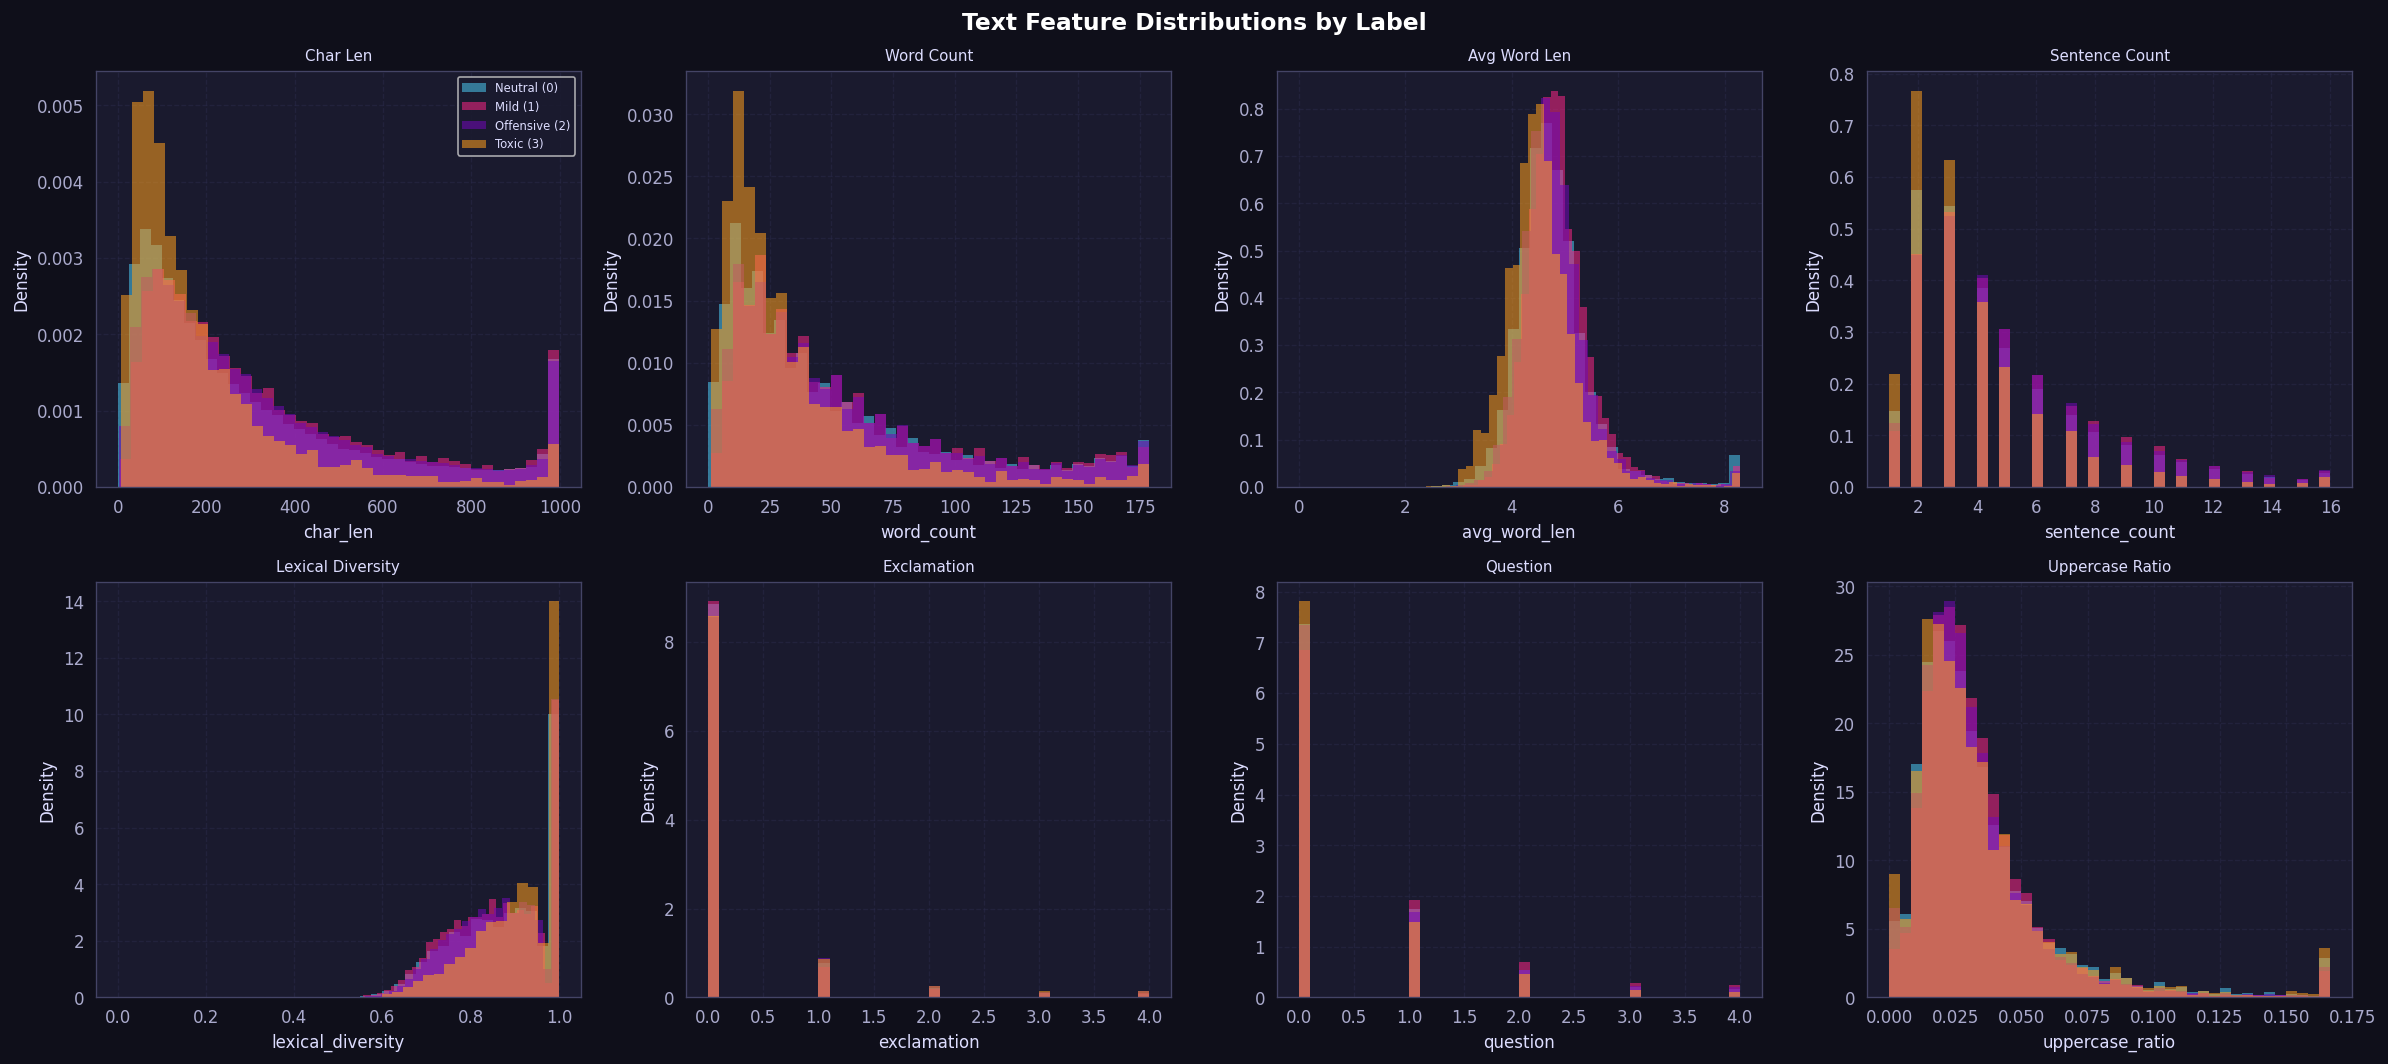

In [28]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
fig.suptitle('Text Feature Distributions by Label', fontsize=14, color='white', fontweight='bold')

for i, metric in enumerate(text_metrics):
    ax = axes[i]
    for lbl, color in zip(sorted(train['label'].unique()), PALETTE):
        subset = train[train['label'] == lbl][metric].clip(upper=train[metric].quantile(0.99))
        ax.hist(subset, bins=40, alpha=0.55, color=color, label=LABEL_NAMES[lbl], density=True, edgecolor='none')
    ax.set_title(metric.replace('_', ' ').title(), fontsize=9)
    ax.set_xlabel(metric); ax.set_ylabel('Density')
    if i == 0:
        ax.legend(fontsize=7)

plt.tight_layout(); plt.show()

#### **<span style='color:#70cccc;'>4.5.5 Kruskal-Wallis Test for Differences in Text Metrics Across Labels </span>**

In [29]:
print('==== Kruskal-Wallis Tests: Text Metrics vs Label ====')
groups = [train[train['label'] == lbl] for lbl in sorted(train['label'].unique())]
results = []
for m in text_metrics:
    g = [grp[m].dropna().values for grp in groups]
    stat, p = kruskal(*g)
    # Eta-squared approximation
    N = sum(len(gi) for gi in g)
    k = len(g)
    eta2 = (stat - k + 1) / (N - k)
    results.append({'metric': m, 'H-stat': stat, 'p-value': p,
                    'sig': '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns')),
                    'eta² (effect)': max(eta2, 0)})

res_train = pd.DataFrame(results).set_index('metric')
display(res_train.round(4))

==== Kruskal-Wallis Tests: Text Metrics vs Label ====


,H-stat,p-value,sig,eta² (effect)
metric,,,,
char_len,2347.6213,0.0,***,0.0118
word_count,2048.5860,0.0,***,0.0103
avg_word_len,1691.8354,0.0,***,0.0085
sentence_count,1555.0738,0.0,***,0.0078
lexical_diversity,1158.1186,0.0,***,0.0058
exclamation,348.9171,0.0,***,0.0017
question,287.7430,0.0,***,0.0014
uppercase_ratio,89.3394,0.0,***,0.0004


### **<span style='color:#70cccc;'>4.6 Feature Correlation Analysis</span>**

#### **<span style='color:#70cccc;'>4.6.1 Pearson Correlation for Inter-Feature and with Label</span>**

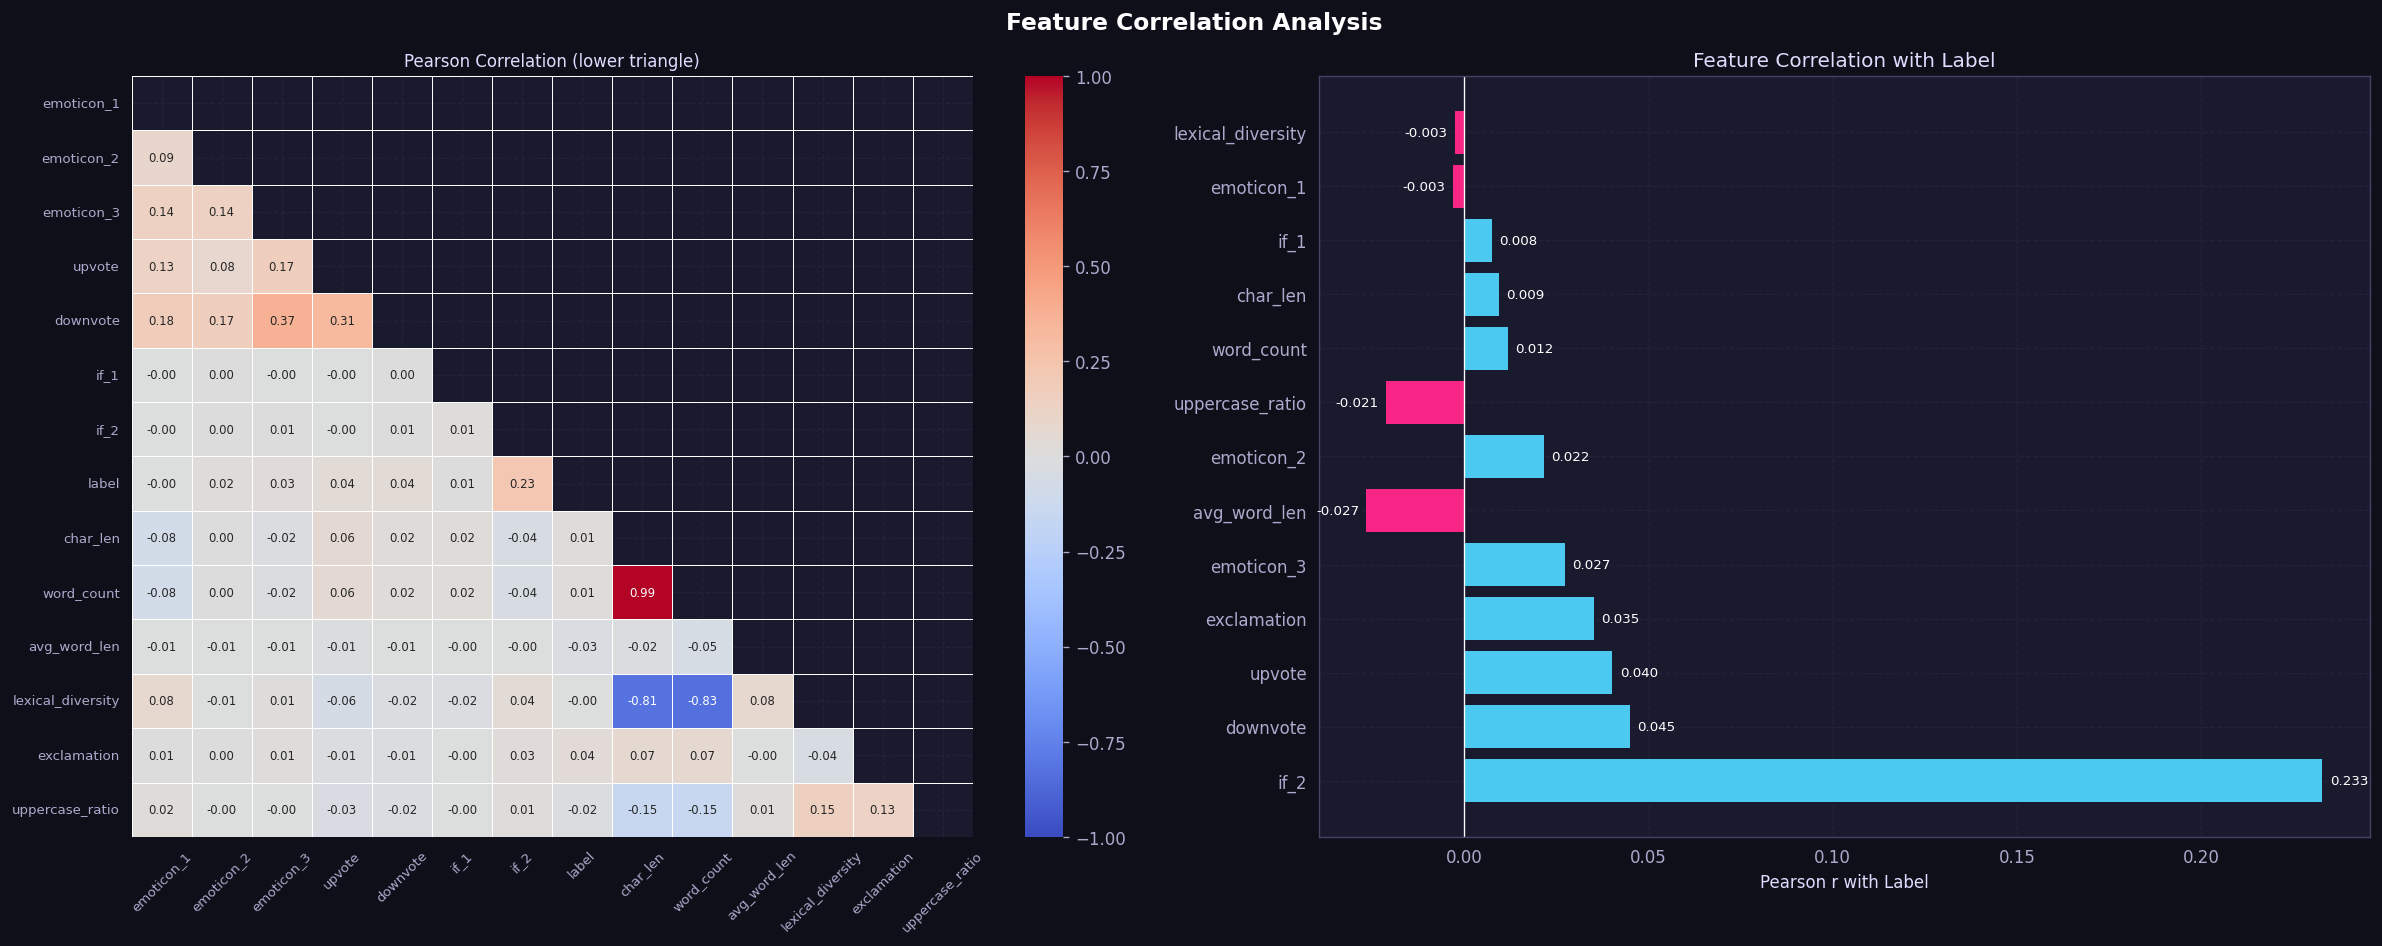

In [30]:
corr_cols = num_cols + ['label', 'char_len', 'word_count', 'avg_word_len',
                        'lexical_diversity', 'exclamation', 'uppercase_ratio']

corr_matrix = train[corr_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle('Feature Correlation Analysis', fontsize=14, color='white', fontweight='bold')

# Pearson heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, ax=axes[0], mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.3,
            annot_kws={'size': 7}, vmin=-1, vmax=1)
axes[0].set_title('Pearson Correlation (lower triangle)', fontsize=10)
axes[0].tick_params(axis='x', rotation=45, labelsize=8)
axes[0].tick_params(axis='y', labelsize=8)

# Correlation with 'label' specifically
label_corr = corr_matrix['label'].drop('label').sort_values(key=abs, ascending=False)
colors = ['#f72585' if v < 0 else '#4cc9f0' for v in label_corr]
axes[1].barh(label_corr.index, label_corr.values, color=colors, edgecolor='none')
axes[1].axvline(0, color='white', linewidth=0.8)
axes[1].set_xlabel('Pearson r with Label'); axes[1].set_title('Feature Correlation with Label')
for i, v in enumerate(label_corr.values):
    axes[1].text(v + (0.002 if v >= 0 else -0.002), i, f'{v:.3f}',
                 va='center', ha='left' if v >= 0 else 'right', fontsize=8, color='white')

plt.tight_layout(); plt.show()

#### **<span style='color:#70cccc;'>4.6.1 Comparison of Pearson and Spearman Correlation with Target Variable</span>**

In [31]:
# Spearman correlation (rank-based, better for skewed distributions)
spearman_corr = train[corr_cols].corr(method='spearman')
label_spearman = spearman_corr['label'].drop('label').sort_values(key=abs, ascending=False)

print('==== Pearson vs Spearman Correlation with Label ====')
comparison = pd.DataFrame({
    'Pearson r': label_corr.reindex(label_spearman.index),
    'Spearman ρ': label_spearman
})
display(comparison.round(4))

==== Pearson vs Spearman Correlation with Label ====


,Pearson r,Spearman ρ
if_2,0.2329,0.8316
if_1,0.0075,0.0799
downvote,0.0449,0.0627
word_count,0.0117,0.0407
char_len,0.0094,0.0398
upvote,0.0402,0.0385
exclamation,0.0352,0.0370
emoticon_3,0.0273,0.0324
emoticon_2,0.0216,0.0233
uppercase_ratio,-0.0214,-0.0167


### **<span style='color:#70cccc;'>4.7 Temporal Analysis</span>**

#### **<span style='color:#70cccc;'>4.7.1 Temporal Feature Extraction and Date Distribution</span>**

In [32]:
train['created_date'] = pd.to_datetime(train['created_date'])

# Parse date parts
train['year']       = train['created_date'].dt.year
train['month']      = train['created_date'].dt.month
train['dayofweek']  = train['created_date'].dt.dayofweek
train['hour']       = train['created_date'].dt.hour

print('Date range:', train['created_date'].min(), '->', train['created_date'].max())
print('Year distribution:')
display(train['year'].value_counts().sort_index())

Date range: 2022-04-29 14:50:48.488476+00:00 -> 2024-06-11 04:41:08.821674+00:00
Year distribution:


year
2022      7517
2023    100405
2024     90078
Name: count, dtype: int64

#### **<span style='color:#70cccc;'>4.7.2 Label Frequency Trend Over Time</span>**

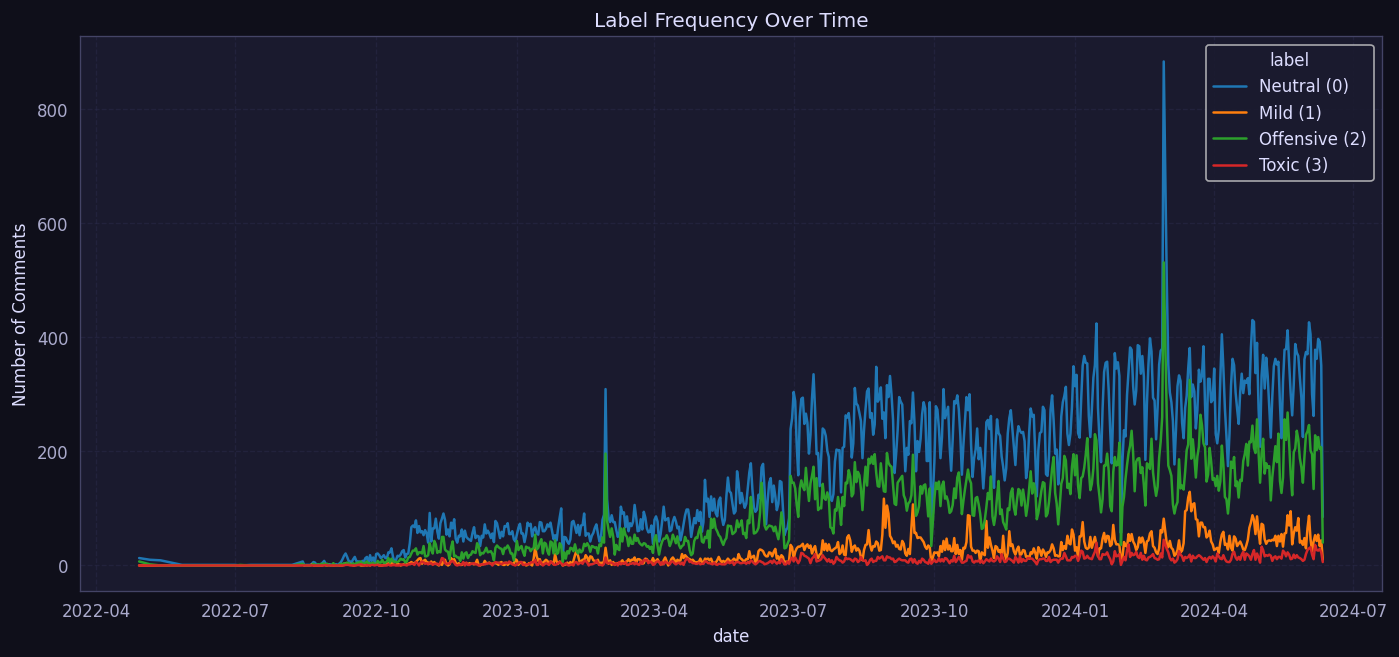

In [33]:
train['date'] = train['created_date'].dt.date

daily = train.groupby(['date', 'label']).size().unstack().fillna(0)

daily.rename(columns=LABEL_NAMES, inplace=True)
daily.plot(figsize=(14,6))
plt.title("Label Frequency Over Time")
plt.ylabel("Number of Comments")
plt.show()

#### **<span style='color:#70cccc;'>4.7.3 Hostility Proportion Over Time</span>**

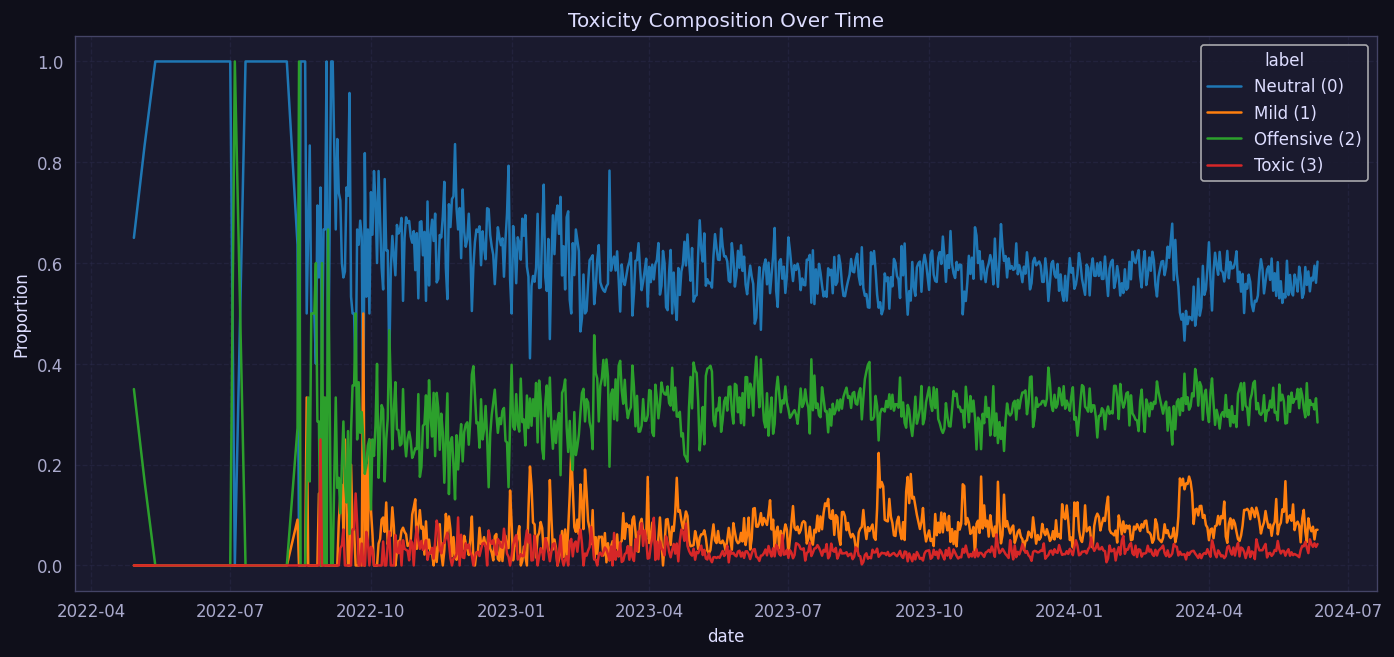

In [34]:
prop = daily.div(daily.sum(axis=1), axis=0)
daily.rename(columns=LABEL_NAMES, inplace=True)
prop.plot(figsize=(14,6))
plt.title("Toxicity Composition Over Time")
plt.ylabel("Proportion")
plt.show()

#### **<span style='color:#70cccc;'>4.7.4 Temporal Distribution of Comments Across Multiple Time Granularities</span>**

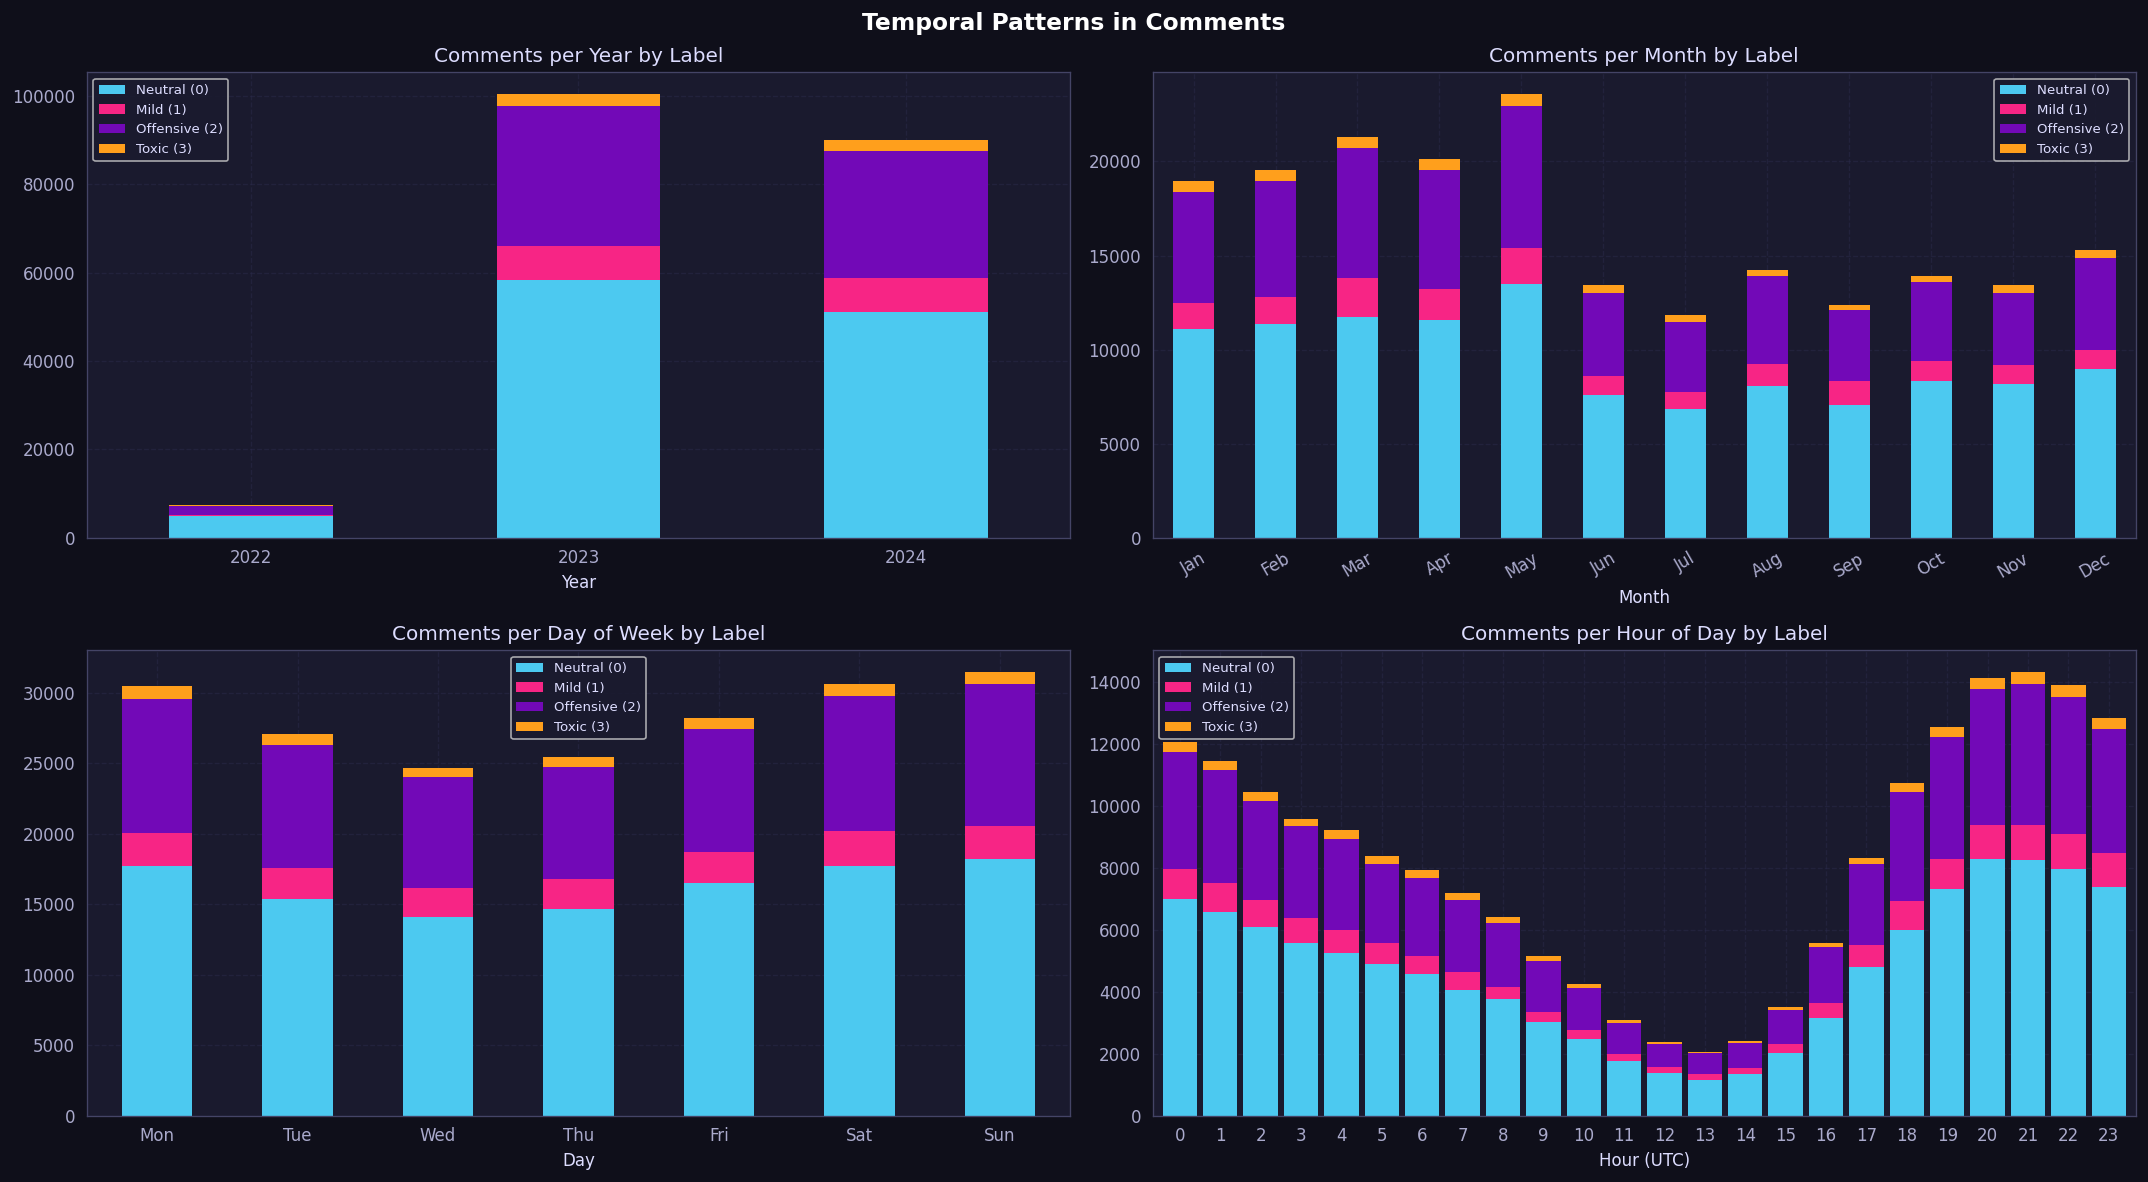

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle('Temporal Patterns in Comments', fontsize=14, color='white', fontweight='bold')
days   = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

# By year
ax = axes[0, 0]
yearly = train.groupby(['year', 'label']).size().unstack(fill_value=0)
yearly.plot(kind='bar', stacked=True, ax=ax, color=PALETTE, edgecolor='none')
ax.set_title('Comments per Year by Label'); ax.set_xlabel('Year')
ax.legend([LABEL_NAMES[i] for i in range(4)], fontsize=8)
ax.tick_params(axis='x', rotation=0)

# By month
ax = axes[0, 1]
monthly = train.groupby(['month', 'label']).size().unstack(fill_value=0)
monthly.plot(kind='bar', stacked=True, ax=ax, color=PALETTE, edgecolor='none')
ax.set_title('Comments per Month by Label'); ax.set_xlabel('Month')
ax.set_xticklabels(months, rotation=30)
ax.legend([LABEL_NAMES[i] for i in range(4)], fontsize=8)

# By day of week
ax = axes[1, 0]
dow = train.groupby(['dayofweek', 'label']).size().unstack(fill_value=0)
dow.plot(kind='bar', stacked=True, ax=ax, color=PALETTE, edgecolor='none')
ax.set_title('Comments per Day of Week by Label'); ax.set_xlabel('Day')
ax.set_xticklabels(days, rotation=0)
ax.legend([LABEL_NAMES[i] for i in range(4)], fontsize=8)

# By hour
ax = axes[1, 1]
hourly = train.groupby(['hour', 'label']).size().unstack(fill_value=0)
hourly.plot(kind='bar', stacked=True, ax=ax, color=PALETTE, edgecolor='none', width=0.85)
ax.set_title('Comments per Hour of Day by Label'); ax.set_xlabel('Hour (UTC)')
ax.legend([LABEL_NAMES[i] for i in range(4)], fontsize=8)
ax.tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.show()

#### **<span style='color:#70cccc;'>4.7.5 Offensive/Toxic Comment Rate by Hour of Day</span>**

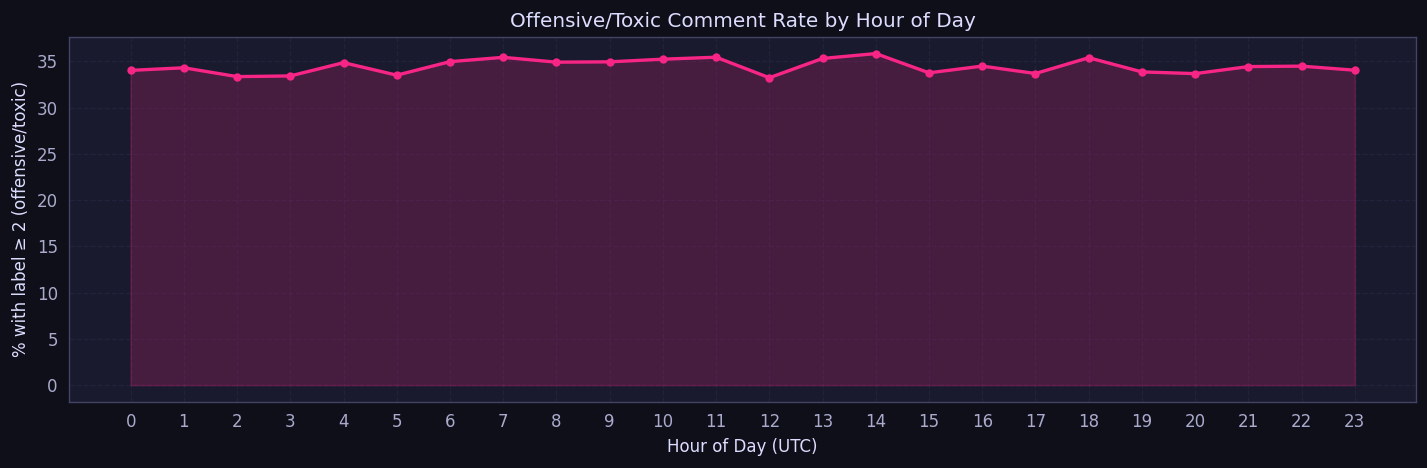

Highest: Hour 14 (35.8%)
Lowest:  Hour 12 (33.2%)


In [36]:
# Toxic comment % by hour — does time of day matter?
hourly_pct = train.groupby('hour')['label'].apply(lambda x: (x >= 2).mean() * 100)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hourly_pct.index, hourly_pct.values, color='#f72585', linewidth=2, marker='o', markersize=4)
ax.fill_between(hourly_pct.index, hourly_pct.values, alpha=0.2, color='#f72585')
ax.set_xlabel('Hour of Day (UTC)'); ax.set_ylabel('% with label ≥ 2 (offensive/toxic)')
ax.set_title('Offensive/Toxic Comment Rate by Hour of Day')
ax.set_xticks(range(0, 24))
plt.tight_layout(); plt.show()

print(f'Highest: Hour {hourly_pct.idxmax()} ({hourly_pct.max():.1f}%)')
print(f'Lowest:  Hour {hourly_pct.idxmin()} ({hourly_pct.min():.1f}%)')

### **<span style='color:#70cccc;'>4.8 Cross-Feature Analysis (Label vs All Features)</span>**


#### **<span style='color:#70cccc;'>4.8.1 Normalized Mean Feature Values Across Labels</span>**

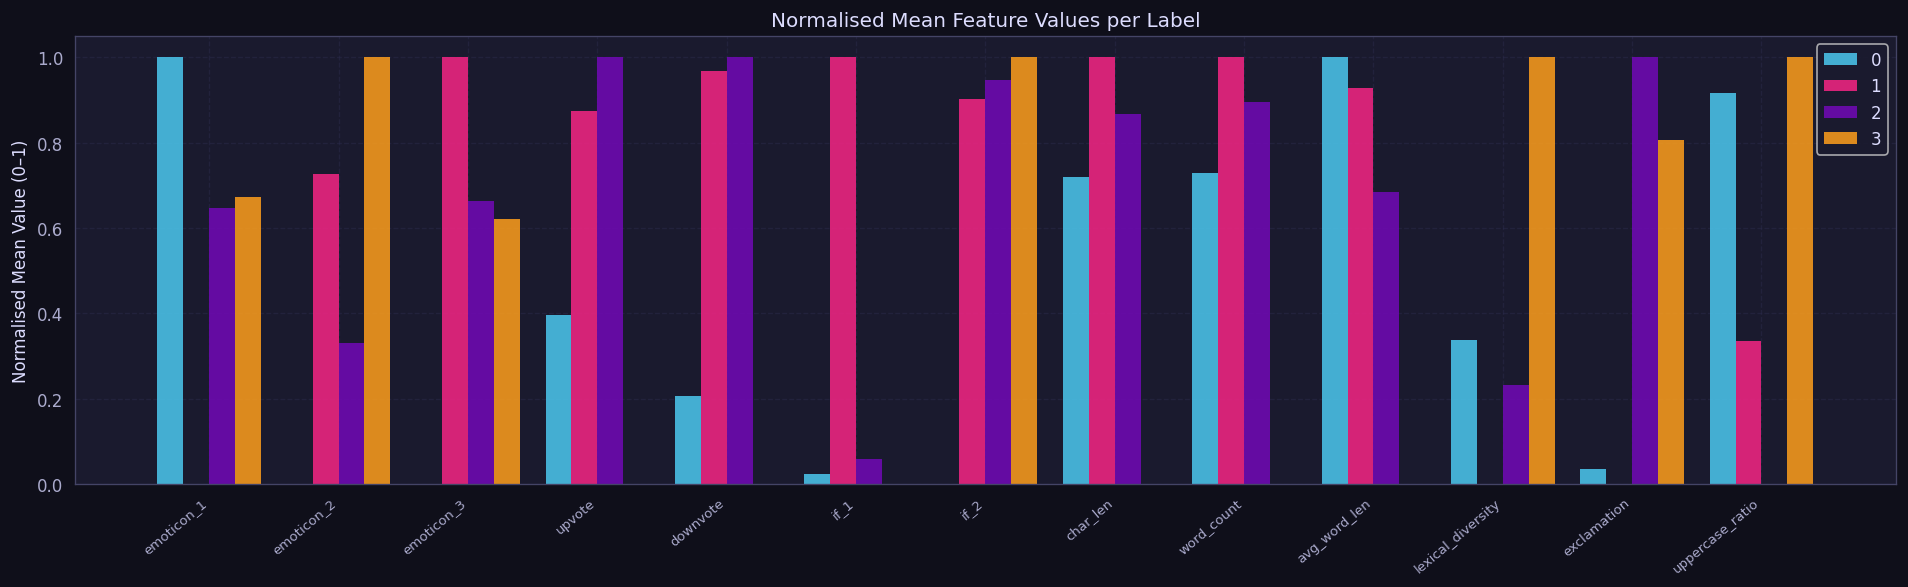

In [37]:
features_to_compare = num_cols + ['char_len', 'word_count', 'avg_word_len',
                                   'lexical_diversity', 'exclamation', 'uppercase_ratio']
group_means = train.groupby('label')[features_to_compare].mean()

normed = (group_means - group_means.min()) / (group_means.max() - group_means.min() + 1e-9)

fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(features_to_compare))
width = 0.2
for i, (lbl, color) in enumerate(zip(sorted(train['label'].unique()), PALETTE)):
    ax.bar(x + i * width, normed.loc[lbl], width=width, label=lbl,
           color=color, alpha=0.85, edgecolor='none')

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(features_to_compare, rotation=40, ha='right', fontsize=8)
ax.set_ylabel('Normalised Mean Value (0–1)')
ax.set_title('Normalised Mean Feature Values per Label')
ax.legend()
plt.tight_layout(); plt.show()

#### **<span style='color:#70cccc;'>4.8.2 Mann-Whitney U Test (Pairwise Comparison of Features: Label 0 vs Label 3)</span>**

In [38]:
print('==== Pairwise Mann-Whitney U: Label 0 vs Label 3 ====')
l0 = train[train['label'] == 0]
l3 = train[train['label'] == 3]

mw_results = []
for feat in features_to_compare:
    stat, p = mannwhitneyu(l0[feat].dropna(), l3[feat].dropna(), alternative='two-sided')
    # Common language effect size
    n0, n3   = len(l0[feat].dropna()), len(l3[feat].dropna())
    cles     = stat / (n0 * n3)
    mw_results.append({'feature': feat, 'U': stat, 'p-value': p,
                        'sig': '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns')),
                        'CLES (effect)': cles})

mw_train = pd.DataFrame(mw_results).set_index('feature').sort_values('p-value')
display(mw_train.round(4))

==== Pairwise Mann-Whitney U: Label 0 vs Label 3 ====


,U,p-value,sig,CLES (effect)
feature,,,,
if_2,21749221.5,0.0000,***,0.0348
char_len,383357539.0,0.0000,***,0.6139
avg_word_len,378706810.5,0.0000,***,0.6065
word_count,376290176.0,0.0000,***,0.6026
lexical_diversity,256899297.0,0.0000,***,0.4114
emoticon_2,305483183.5,0.0000,***,0.4892
upvote,331203900.5,0.0000,***,0.5304
exclamation,303979615.0,0.0000,***,0.4868
emoticon_3,305808181.5,0.0000,***,0.4898


> Although most features are statistically significant, only a few show meaningful effect sizes. Features like character length and word count show moderate differences between labels, while features like if_2 show a strong directional effect, and others are essentially non-informative.
>
> Text length features are more discriminative than engagement or emoticon-based features.

### **<span style='color:#70cccc;'>4.9 Outlier Detection</span>**

In [39]:
print('==== Outlier Analysis (IQR method) ====')
outlier_summary = []
for col in features_to_compare:
    Q1  = train[col].quantile(0.25)
    Q3  = train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((train[col] < lower) | (train[col] > upper)).sum()
    pct   = n_out / len(train) * 100
    outlier_summary.append({'feature': col, 'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
                             'Lower fence': lower, 'Upper fence': upper,
                             'Outliers': n_out, 'Outlier %': pct})

out_df = pd.DataFrame(outlier_summary).set_index('feature')
display(out_df.round(3))

==== Outlier Analysis (IQR method) ====


,Q1,Q3,IQR,Lower fence,Upper fence,Outliers,Outlier %
feature,,,,,,,
emoticon_1,0.000,0.000,0.000,0.000,0.000,28922,14.607
emoticon_2,0.000,0.000,0.000,0.000,0.000,8109,4.095
emoticon_3,0.000,0.000,0.000,0.000,0.000,17165,8.669
upvote,0.000,3.000,3.000,-4.500,7.500,17304,8.739
downvote,0.000,1.000,1.000,-1.500,2.500,15173,7.663
if_1,0.000,4.000,4.000,-6.000,10.000,85,0.043
if_2,4.000,10.000,6.000,-5.000,19.000,3930,1.985
char_len,102.000,419.000,317.000,-373.500,894.500,12822,6.476
word_count,18.000,73.000,55.000,-64.500,155.500,11131,5.622


> Using the IQR method, I identified outliers across features. However, for zero-inflated features like emoticons, many values are flagged as outliers due to sparsity rather than true anomalies, while features like upvotes and text length show genuine heavy-tailed behavior.
>
> IQR-based outlier detection can be misleading for sparse features.

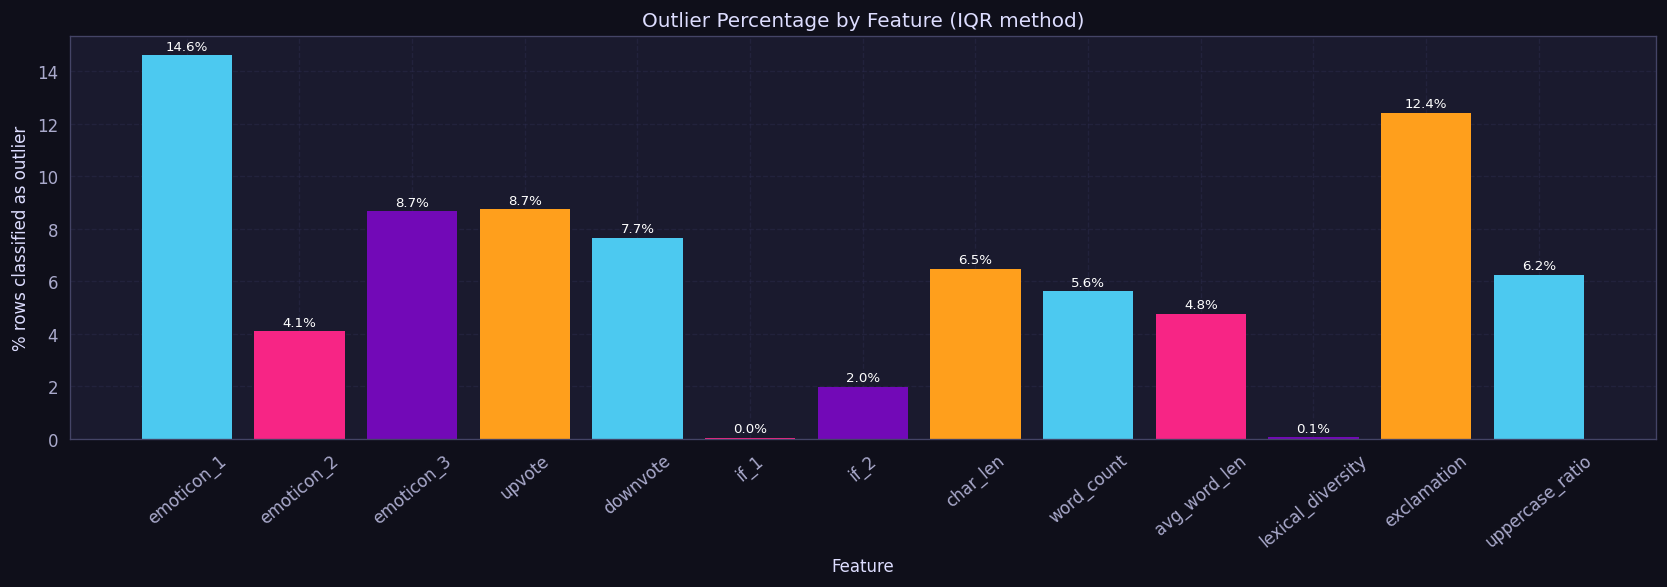

In [40]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(out_df.index, out_df['Outlier %'],
       color=[PALETTE[i % 4] for i in range(len(out_df))], edgecolor='none')
for i, v in enumerate(out_df['Outlier %']):
    ax.text(i, v + 0.1, f'{v:.1f}%', ha='center', va='bottom', fontsize=8, color='white')
ax.set_xlabel('Feature'); ax.set_ylabel('% rows classified as outlier')
ax.set_title('Outlier Percentage by Feature (IQR method)')
ax.tick_params(axis='x', rotation=40)
plt.tight_layout(); plt.show()

## **<span style='color:#70cccc;'>5. Data Preprocessing & Natural Language Processing</span>**

### **<span style='color:#70cccc;'>5.1 Basic Cleaning (Null Texts + Duplicates)</span>**

In [41]:
n_before = len(train)
train = train.dropna(subset=['comment']).copy()
print(f'Dropped {n_before - len(train)} null-comment row(s). Remaining: {len(train):,}')

dup_counts = train['comment'].value_counts()
n_dup_texts = (dup_counts > 1).sum()
print(f'\nUnique comment texts appearing >1 time: {n_dup_texts}')
print('Top 10 most repeated texts:')
display(dup_counts.head(10).to_frame('count'))

Dropped 1 null-comment row(s). Remaining: 197,999

Unique comment texts appearing >1 time: 103
Top 10 most repeated texts:


,count
comment,
Exactly..,8
Troll,8
Exactly,6
Yes,6
No,6
Liar,5
Well said,5
What?,4
Good,4


* Keeping all duplicates; same text may carry different labels.

### **<span style='color:#70cccc;'>5.2 Text Processing</span>**


In [42]:
STOPWORDS = frozenset([
    'a','about','above','after','again','against','all','am','an','and','any',
    'are','as','at','be','because','been','before','being','below','between',
    'both','but','by','can','did','do','does','doing','down','during','each',
    'few','for','from','further','get','got','had','has','have','having','he',
    'her','here','hers','herself','him','himself','his','how','i','if','in',
    'into','is','it','its','itself','just','me','more','most','my','myself',
    'no','nor','not','now','of','off','on','once','only','or','other','our',
    'ours','ourselves','out','own','same','she','should','so','some','such',
    'than','that','the','their','theirs','them','themselves','then','there',
    'these','they','this','those','through','to','too','under','until','up',
    'us','very','was','we','were','what','when','where','which','while','who',
    'whom','why','will','with','you','your','yours','yourself','yourselves',
    'also','may','might','shall','would','could','cannot','let','ve','ll','re',
    'd','s','m','t',
])


CONTRACTIONS = {
    "won't":"will not",  "can't":"cannot",      "i'm":"i am",
    "i've":"i have",     "i'll":"i will",        "i'd":"i would",
    "you're":"you are",  "you've":"you have",    "you'll":"you will",
    "you'd":"you would", "he's":"he is",         "he'd":"he would",
    "she's":"she is",    "she'd":"she would",    "it's":"it is",
    "we're":"we are",    "we've":"we have",      "we'll":"we will",
    "we'd":"we would",   "they're":"they are",   "they've":"they have",
    "they'll":"they will","they'd":"they would","that's":"that is",
    "isn't":"is not",    "aren't":"are not",     "wasn't":"was not",
    "weren't":"were not","haven't":"have not",   "hasn't":"has not",
    "hadn't":"had not",  "wouldn't":"would not", "couldn't":"could not",
    "shouldn't":"should not", "doesn't":"does not", "don't":"do not",
    "didn't":"did not",  "let's":"let us",        "what's":"what is",
    "who's":"who is",    "where's":"where is",   "there's":"there is",
    "n't":" not",
}

_CONTRACTION_RE = re.compile(
    r'\b(' + '|'.join(re.escape(k) for k in sorted(CONTRACTIONS, key=len, reverse=True)) + r')\b',
    re.IGNORECASE
)

def expand_contractions(text):
    return _CONTRACTION_RE.sub(lambda m: CONTRACTIONS.get(m.group(0).lower(), m.group(0)), text)

print('Stopword list size:', len(STOPWORDS))
print('Contraction mappings:', len(CONTRACTIONS))

Stopword list size: 141
Contraction mappings: 43


In [43]:
_SUFFIX_RULES = [
    ('ational', 'ate'), ('tional', 'tion'), ('enci', 'ence'), ('anci', 'ance'),
    ('izer', 'ize'),    ('ising', 'ise'),   ('izing', 'ize'), ('ising', 'ise'),
    ('ational', 'ate'), ('alism', 'al'),    ('iveness', 'ive'), ('fulness', 'ful'),
    ('ousness', 'ous'), ('aliti', 'al'),    ('iviti', 'ive'), ('biliti', 'ble'),
    ('icate', 'ic'),    ('ical', 'ic'),     ('alize', 'al'), ('iciti', 'ic'),
    ('ness', ''),       ('ment', ''),       ('ation', 'ate'), ('ations', 'ate'),
    ('ating', 'ate'),   ('ated', 'ate'),    ('ates', 'ate'),  ('ator', 'ate'),
    ('alism', 'al'),    ('alise', 'al'),    ('alize', 'al'),
    ('sses', 'ss'),     ('ies', 'i'),       ('ing', ''),      ('ed', ''),
    ('ies', 'y'),       ('ier', 'y'),       ('iest', 'y'),    ('ness', ''),
    ('er', ''),         ('ly', ''),         ('ers', ''),      ('s', ''),
]

def stem_word(word):
    if len(word) <= 3:
        return word
    for suffix, replacement in _SUFFIX_RULES:
        if word.endswith(suffix) and len(word) - len(suffix) >= 3:
            return word[:-len(suffix)] + replacement
    return word

tests = ['running', 'happiness', 'nationalization', 'quickly', 'dogs']
for t in tests:
    print(f'  {t:20s} → {stem_word(t)}')

  running              → runn
  happiness            → happi
  nationalization      → nationalizate
  quickly              → quick
  dogs                 → dog


In [44]:
# Full NLP cleaning pipeline 

_PUNCT_TABLE = str.maketrans(string.punctuation, ' ' * len(string.punctuation))
_MULTI_SPACE = re.compile(r'\s+')
_URL_RE      = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
_HTML_RE     = re.compile(r'<[^>]+>')
_NON_ASCII   = re.compile(r'[^\x00-\x7F]+')
_ALPHA_TOK   = re.compile(r'[a-z]+')

def clean_text(text, remove_stopwords=True, do_stem=True):
    """
    NLP pipeline (NO external NLP library):
      1. Guard against non-string
      2. Lowercase
      3. Remove URLs
      4. Remove HTML tags
      5. Expand contractions
      6. Replace punctuation with spaces
      7. Remove non-ASCII characters
      8. Tokenise (extract alpha-only tokens with regex)
      9. Remove stopwords
     10. Suffix-strip stemming
     11. Rejoin
    """
    if not isinstance(text, str) or not text.strip():
        return ''
    text = text.lower()
    text = _URL_RE.sub(' ', text)
    text = _HTML_RE.sub(' ', text)
    text = expand_contractions(text)
    text = text.translate(_PUNCT_TABLE)
    text = _NON_ASCII.sub(' ', text)
    tokens = _ALPHA_TOK.findall(text)          # pure alpha tokens only
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 1]
    if do_stem:
        tokens = [stem_word(t) for t in tokens]
    return ' '.join(tokens)


def light_clean(text):
    """
    Minimal clean (preserve casing, punctuation, stopwords).
    For bag-of-words models that may benefit from punctuation signals.
    """
    if not isinstance(text, str):
        return ''
    text = _URL_RE.sub(' ', text)
    text = _HTML_RE.sub(' ', text)
    text = _NON_ASCII.sub(' ', text)
    return _MULTI_SPACE.sub(' ', text).strip()


print('Cleaning train text...')
train['comment_clean'] = train['comment'].apply(clean_text)
train['comment_light'] = train['comment'].apply(light_clean)

print('Cleaning test text...')
test['comment_clean'] = test['comment'].apply(clean_text)
test['comment_light'] = test['comment'].apply(light_clean)

i = 10
print(f'\nOriginal : {train["comment"].iloc[i][:200]}')
print(f'Cleaned  : {train["comment_clean"].iloc[i][:200]}')
print(f'Light    : {train["comment_light"].iloc[i][:200]}')

Cleaning train text...
Cleaning test text...

Original : You're right the words Muslim ban came straight from trump.
Cleaned  : right word muslim ban came straight trump
Light    : You're right the words Muslim ban came straight from trump.


In [45]:
# Pipeline coverage check 
n_empty_after = (train['comment_clean'] == '').sum()
print(f'Empty strings after cleaning: {n_empty_after}')

# Avg token count before/after stop-word removal
raw_tokens  = train['comment'].fillna('').str.split().str.len()
clean_tokens= train['comment_clean'].str.split().str.len()
print(f'Avg word count — raw: {raw_tokens.mean():.1f}  |  cleaned: {clean_tokens.mean():.1f}')
print(f'Vocab compression  : {clean_tokens.mean()/raw_tokens.mean()*100:.0f} % of original')

Empty strings after cleaning: 264
Avg word count — raw: 52.4  |  cleaned: 26.5
Vocab compression  : 51 % of original



### **<span style='color:#70cccc;'>5.3 Text Feature Engineering</span>**

In [46]:
# Features derived from the RAW / LIGHT-CLEANED text (before stopword removal)
# so stylistic signals (punctuation, casing) are still present.

def extract_text_features(df, col='comment'):
    """
    Returns a DataFrame of per-row text statistics.
    EDA showed these are statistically significant across labels.
    """
    text  = df[col].fillna('')
    words = text.str.split()

    f = pd.DataFrame(index=df.index)

    # --- Length / structure ---
    f['char_len']           = text.str.len()
    f['word_count']         = words.str.len().fillna(0).astype(int)
    f['sentence_count']     = text.str.count(r'[.!?]+') + 1
    f['avg_word_len']       = words.apply(
        lambda ws: np.mean([len(w) for w in ws]) if ws and len(ws) > 0 else 0)
    f['avg_sentence_len']   = f['word_count'] / f['sentence_count'].clip(lower=1)

    # --- Lexical diversity ---
    f['unique_word_ratio']  = text.apply(
        lambda t: len(set(t.lower().split())) / max(len(t.split()), 1))

    # --- Stylistic / affect signals ---
    f['uppercase_ratio']    = text.apply(
        lambda t: sum(1 for c in t if c.isupper()) / max(len(t), 1))
    f['exclamation_cnt']    = text.str.count('!')
    f['question_cnt']       = text.str.count(r'\?')
    f['special_char_cnt']   = text.apply(
        lambda t: sum(1 for c in t if not c.isalnum() and c != ' '))
    f['digit_ratio']        = text.apply(
        lambda t: sum(c.isdigit() for c in t) / max(len(t), 1))

    # --- Punctuation density ---
    f['punct_density']      = text.apply(
        lambda t: sum(c in string.punctuation for c in t) / max(len(t), 1))

    # --- Capitalised words count (ALL-CAPS words, a toxicity marker) ---
    f['all_caps_word_cnt']  = words.apply(
        lambda ws: sum(1 for w in ws if w.isupper() and len(w) > 1) if ws else 0)

    return f


text_feats_train = extract_text_features(train)
text_feats_test  = extract_text_features(test)

print('Text feature shapes:', text_feats_train.shape, text_feats_test.shape)
display(text_feats_train.describe().round(3))

Text feature shapes: (197999, 13) (102000, 13)


,char_len,word_count,sentence_count,avg_word_len,avg_sentence_len,unique_word_ratio,uppercase_ratio,exclamation_cnt,question_cnt,special_char_cnt,digit_ratio,punct_density,all_caps_word_cnt
count,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000
mean,302.911,52.397,4.751,4.908,10.578,0.869,0.036,0.224,0.440,10.775,0.004,0.038,0.687
std,266.442,45.770,3.233,2.804,6.460,0.106,0.043,0.952,0.992,11.237,0.013,0.033,2.190
min,1.000,1.000,1.000,1.000,0.167,0.055,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,102.000,18.000,2.000,4.389,6.333,0.789,0.018,0.000,0.000,3.000,0.000,0.022,0.000
50%,211.000,37.000,4.000,4.714,9.667,0.878,0.027,0.000,0.000,7.000,0.000,0.031,0.000
75%,419.000,73.000,6.000,5.083,13.571,0.962,0.041,0.000,1.000,14.000,0.000,0.045,1.000
max,1892.000,315.000,57.000,333.000,188.000,1.000,1.000,96.000,49.000,506.000,1.000,1.000,158.000


In [47]:
# ── Kruskal-Wallis significance test for each text feature vs label ────────────
from scipy.stats import kruskal

groups = [train[train['label'] == lbl] for lbl in sorted(train['label'].unique())]
rows = []
for feat in text_feats_train.columns:
    g = [text_feats_train.loc[grp.index, feat].dropna().values for grp in groups]
    stat, p = kruskal(*g)
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    rows.append({'feature': feat, 'H': round(stat, 2), 'p-value': f'{p:.2e}', 'sig': sig})

kw_df = pd.DataFrame(rows).set_index('feature').sort_values('H', ascending=False)
display(kw_df)

,H,p-value,sig
feature,,,
char_len,2347.48,0.00e+00,***
word_count,2048.44,0.00e+00,***
avg_word_len,1691.75,0.00e+00,***
special_char_cnt,1622.47,0.00e+00,***
sentence_count,1554.94,0.00e+00,***
digit_ratio,1161.24,1.88e-251,***
unique_word_ratio,1158.22,8.49e-251,***
avg_sentence_len,1038.97,6.32e-225,***
exclamation_cnt,348.90,2.59e-75,***


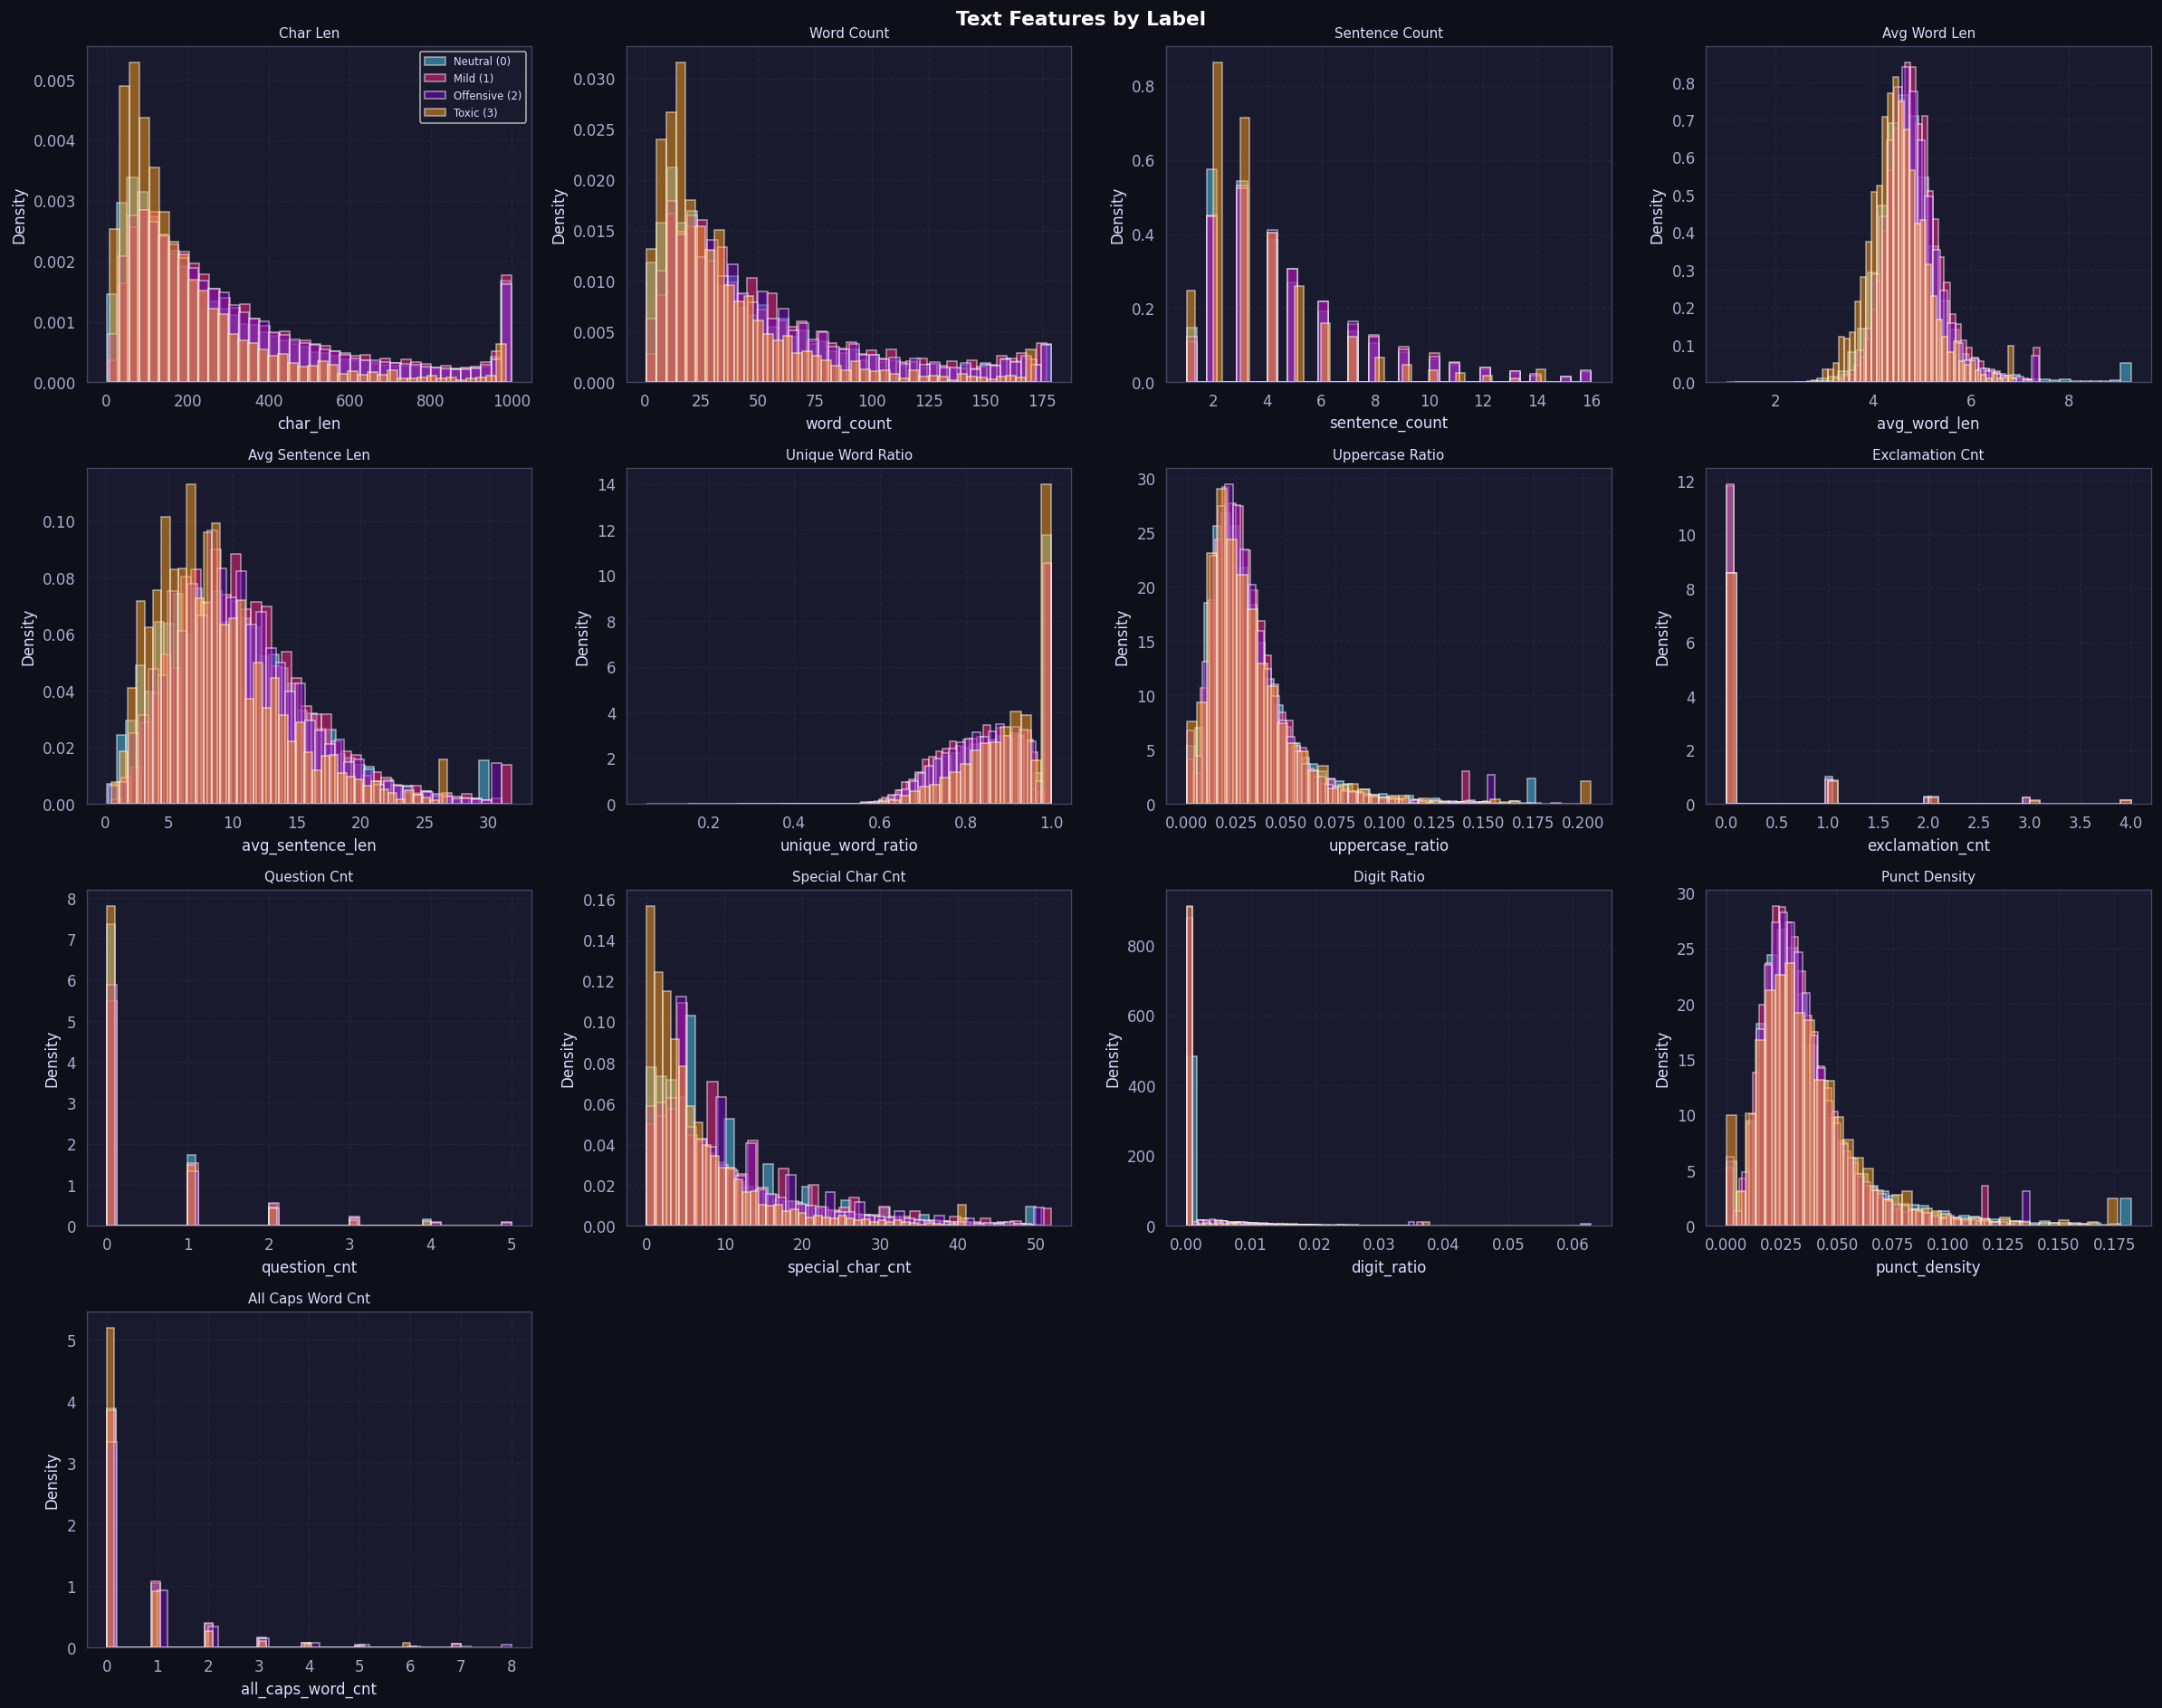

In [48]:
# Distribution by label 
feat_viz = text_feats_train.copy()
feat_viz['label'] = train['label'].values

cols_to_plot = text_feats_train.columns.tolist()
n = len(cols_to_plot)
ncols, nrows = 4, (n + 3) // 4

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 4))
axes = axes.flatten()
fig.suptitle('Text Features by Label', fontsize=13, color='white', fontweight='bold')

for i, feat in enumerate(cols_to_plot):
    ax = axes[i]
    for lbl, color in zip(sorted(train['label'].unique()), PALETTE):
        data = feat_viz[feat_viz['label'] == lbl][feat]
        data = data.clip(upper=data.quantile(0.99))
        ax.hist(data, bins=40, alpha=0.5, color=color, label=LABEL_NAMES[lbl], density=True)
    ax.set_title(feat.replace('_', ' ').title(), fontsize=9)
    ax.set_xlabel(feat); ax.set_ylabel('Density')
    if i == 0: ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout(); plt.show()


### **<span style='color:#70cccc;'>5.4 Metadata Feature Engineering</span>**

In [49]:
def build_metadata_features(df):
    feats = pd.DataFrame(index=df.index)

    # Raw numeric features 
    feats['emoticon_1']    = df['emoticon_1']
    feats['emoticon_2']    = df['emoticon_2']
    feats['emoticon_3']    = df['emoticon_3']
    feats['emoticon_sum']  = df['emoticon_1'] + df['emoticon_2'] + df['emoticon_3']
    feats['upvote']        = df['upvote']
    feats['downvote']      = df['downvote']

    # Vote-ratio (avoids div-by-zero with +1 smoothing)
    total_votes = df['upvote'] + df['downvote']
    feats['upvote_ratio']  = df['upvote'] / (total_votes + 1)
    feats['vote_sum']      = total_votes

    # if_1, if_2 — clip extreme outliers at 99th percentile (EDA: max ~1860)
    if_1_cap = df['if_1'].quantile(0.99)
    if_2_cap = df['if_2'].quantile(0.99)
    feats['if_1_clipped']  = df['if_1'].clip(upper=if_1_cap)
    feats['if_2_clipped']  = df['if_2'].clip(upper=if_2_cap)
    feats['if_ratio']      = feats['if_1_clipped'] / (feats['if_2_clipped'] + 1)

    # Log-transforms for skewed features 
    for col in ['upvote', 'downvote', 'vote_sum', 'if_1_clipped', 'if_2_clipped']:
        feats[f'log_{col}'] = np.log1p(feats[col])

    # Demographic signals 
    # 73 % of race/religion/gender are co-missing → one binary flag captures it
    feats['has_demographic'] = (~df['race'].isnull()).astype(int)
    feats['disability']      = df['disability'].astype(int)

    # Temporal features 
    hour      = df['created_date'].dt.hour
    dayofweek = df['created_date'].dt.dayofweek
    month     = df['created_date'].dt.month

    # Cyclical encoding — preserves 23h→0h continuity etc.
    feats['hour_sin']       = np.sin(2 * np.pi * hour      / 24)
    feats['hour_cos']       = np.cos(2 * np.pi * hour      / 24)
    feats['dayofweek_sin']  = np.sin(2 * np.pi * dayofweek / 7)
    feats['dayofweek_cos']  = np.cos(2 * np.pi * dayofweek / 7)
    feats['month_sin']      = np.sin(2 * np.pi * month     / 12)
    feats['month_cos']      = np.cos(2 * np.pi * month     / 12)

    return feats


meta_feats_train = build_metadata_features(train)
meta_feats_test  = build_metadata_features(test)

print('Metadata feature shapes:', meta_feats_train.shape, meta_feats_test.shape)
display(meta_feats_train.describe().round(3))

Metadata feature shapes: (197999, 24) (102000, 24)


,emoticon_1,emoticon_2,emoticon_3,emoticon_sum,upvote,downvote,upvote_ratio,vote_sum,if_1_clipped,if_2_clipped,...,log_if_1_clipped,log_if_2_clipped,has_demographic,disability,hour_sin,hour_cos,dayofweek_sin,dayofweek_cos,month_sin,month_cos
count,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,...,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000,197999.000
mean,0.280,0.048,0.121,0.449,2.608,0.666,0.375,3.274,1.508,7.794,...,0.489,2.014,0.266,0.014,-0.073,0.310,-0.053,0.032,0.139,-0.006
std,1.023,0.258,0.481,1.254,5.055,2.044,0.339,6.019,2.806,8.247,...,0.830,0.477,0.442,0.117,0.725,0.610,0.703,0.708,0.702,0.698
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,3.000,...,0.000,1.386,0.000,0.000,-1.000,-1.000,-0.975,-0.901,-1.000,-1.000
25%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4.000,...,0.000,1.609,0.000,0.000,-0.866,-0.259,-0.782,-0.901,-0.500,-0.500
50%,0.000,0.000,0.000,0.000,1.000,0.000,0.500,1.000,0.000,6.000,...,0.000,1.946,0.000,0.000,-0.259,0.500,0.000,-0.223,0.500,0.000
75%,0.000,0.000,0.000,0.000,3.000,1.000,0.667,4.000,4.000,10.000,...,1.609,2.398,1.000,0.000,0.707,0.866,0.782,0.623,0.866,0.500
max,47.000,11.000,17.000,60.000,201.000,107.000,0.994,241.000,10.000,66.000,...,2.398,4.205,1.000,1.000,1.000,1.000,0.975,1.000,1.000,1.000


### **<span style='color:#70cccc;'>5.5 Categorical Encoding</span>**

In [50]:
CAT_COLS = ['race', 'religion', 'gender']

def encode_categoricals(df, ref_columns=None):
    filled   = df[CAT_COLS].fillna('none')
    encoded  = pd.get_dummies(filled, prefix=CAT_COLS)
    # Align to reference column set (from train) if supplied
    if ref_columns is not None:
        encoded = encoded.reindex(columns=ref_columns, fill_value=0)
    return encoded

cat_feats_train = encode_categoricals(train)
cat_feats_test  = encode_categoricals(test, ref_columns=cat_feats_train.columns)

print('Categorical feature shapes:', cat_feats_train.shape, cat_feats_test.shape)
print('Columns:', cat_feats_train.columns.tolist())

# Save column reference for future use
CAT_COLUMNS = cat_feats_train.columns.tolist()

Categorical feature shapes: (197999, 19) (102000, 19)
Columns: ['race_asian', 'race_black', 'race_latino', 'race_none', 'race_other', 'race_white', 'religion_atheist', 'religion_buddhist', 'religion_christian', 'religion_hindu', 'religion_jewish', 'religion_muslim', 'religion_none', 'religion_other', 'gender_female', 'gender_male', 'gender_none', 'gender_other', 'gender_transgender']


### **<span style='color:#70cccc;'>5.6 Feature Scaling</span>**

In [51]:
# Combine all dense features
dense_train = pd.concat([text_feats_train, meta_feats_train, cat_feats_train], axis=1)
dense_test  = pd.concat([text_feats_test,  meta_feats_test,  cat_feats_test],  axis=1)

print('Dense feature matrix shapes:', dense_train.shape, dense_test.shape)

# StandardScaler fit on TRAIN ONLY — prevent data leakage
scaler = StandardScaler()
dense_train_scaled = scaler.fit_transform(dense_train)
dense_test_scaled  = scaler.transform(dense_test)

print('Scaling complete.')

DENSE_COL_NAMES = dense_train.columns.tolist()
print(f'Total dense features: {len(DENSE_COL_NAMES)}')

Dense feature matrix shapes: (197999, 56) (102000, 56)
Scaling complete.
Total dense features: 56



### **<span style='color:#70cccc;'>5.7 Class Imbalance - Analysis & Strategy</span>**

In [52]:
y_train = train['label'].values

lbl_counts = pd.Series(y_train).value_counts().sort_index()
print('Label distribution:')
for lbl, cnt in lbl_counts.items():
    print(f'  {LABEL_NAMES[lbl]:18s}: {cnt:7,}  ({cnt/len(y_train)*100:.2f}%)')
print(f'  Imbalance ratio (max/min): {lbl_counts.max()/lbl_counts.min():.1f}x')

# Balanced class weights for sklearn / XGBoost
classes      = np.unique(y_train)
cw_values    = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, cw_values))
print('\nBalanced class weights:')
for lbl, w in class_weight_dict.items():
    print(f'  Label {lbl}: {w:.4f}')

Label distribution:
  Neutral (0)       : 114,172  (57.66%)
  Mild (1)          :  15,918  (8.04%)
  Offensive (2)     :  62,440  (31.54%)
  Toxic (3)         :   5,469  (2.76%)
  Imbalance ratio (max/min): 20.9x

Balanced class weights:
  Label 0: 0.4336
  Label 1: 3.1097
  Label 2: 0.7928
  Label 3: 9.0510


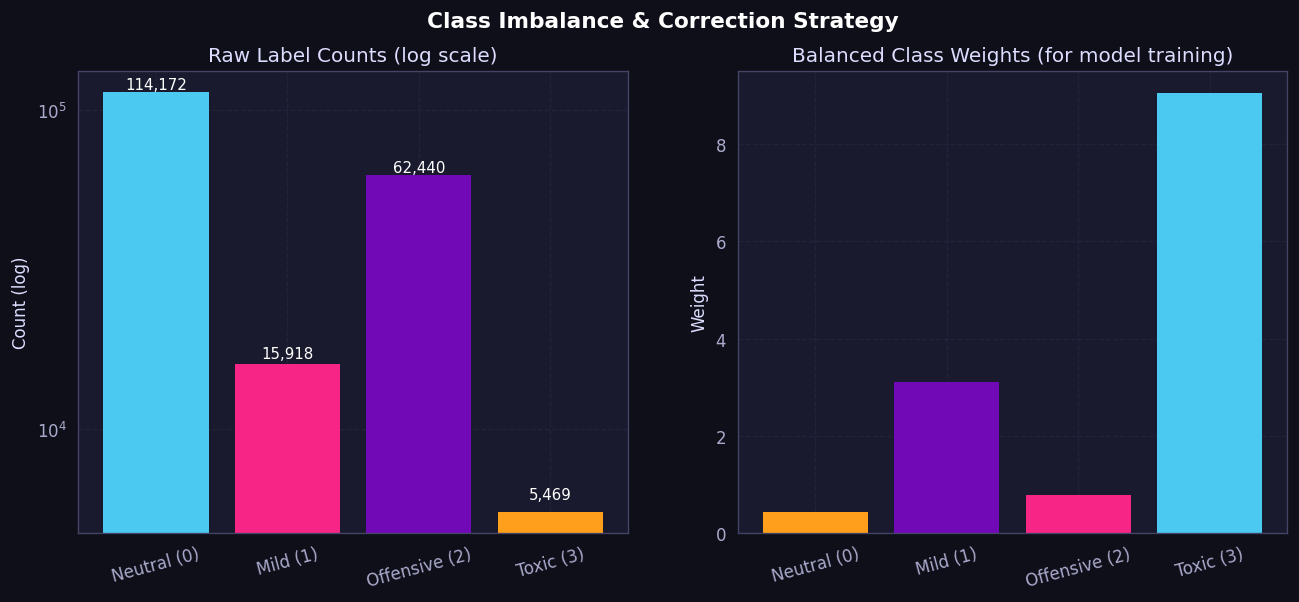

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Class Imbalance & Correction Strategy', fontsize=13, color='white', fontweight='bold')

ax = axes[0]
bars = ax.bar([LABEL_NAMES[i] for i in lbl_counts.index], lbl_counts.values, color=PALETTE, edgecolor='none')
for bar, cnt in zip(bars, lbl_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
            f'{cnt:,}', ha='center', va='bottom', fontsize=9, color='white')
ax.set_yscale('log')
ax.set_title('Raw Label Counts (log scale)'); ax.set_ylabel('Count (log)')
ax.tick_params(axis='x', rotation=15)

ax = axes[1]
ax.bar([LABEL_NAMES[i] for i in sorted(class_weight_dict)],
       [class_weight_dict[i] for i in sorted(class_weight_dict)], color=PALETTE[::-1], edgecolor='none')
ax.set_title('Balanced Class Weights (for model training)')
ax.set_ylabel('Weight'); ax.tick_params(axis='x', rotation=15)


### **<span style='color:#70cccc;'>5.8 TF-IDF Vectorisation</span>**

In [54]:
tfidf_word = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=100_000,
    sublinear_tf=True,
    min_df=3,
    max_df=0.95,
    strip_accents='unicode',
    analyzer='word',
)
X_tfidf_word_train = tfidf_word.fit_transform(train['comment_clean'])
X_tfidf_word_test  = tfidf_word.transform(test['comment_clean'])

print(f'Word TF-IDF — train: {X_tfidf_word_train.shape}  |  test: {X_tfidf_word_test.shape}')
print(f'Vocabulary size: {len(tfidf_word.vocabulary_):,}')

Word TF-IDF — train: (197999, 100000)  |  test: (102000, 100000)
Vocabulary size: 100,000


In [55]:
tfidf_char = TfidfVectorizer(
    ngram_range=(3, 5),
    max_features=60_000,
    sublinear_tf=True,
    min_df=5,
    max_df=0.95,
    strip_accents='unicode',
    analyzer='char_wb', 
)
X_tfidf_char_train = tfidf_char.fit_transform(train['comment_light'])
X_tfidf_char_test  = tfidf_char.transform(test['comment_light'])

print(f'Char TF-IDF  — train: {X_tfidf_char_train.shape}  |  test: {X_tfidf_char_test.shape}')

Char TF-IDF  — train: (197999, 60000)  |  test: (102000, 60000)


In [56]:
# Inspect top TF-IDF terms per label (word-level) 
vocab = np.array(tfidf_word.get_feature_names_out())
print('Top-15 word TF-IDF terms per label (mean weight):')
for lbl in sorted(np.unique(y_train)):
    mask   = y_train == lbl
    # mean over only the rows of that class
    means  = np.asarray(X_tfidf_word_train[mask].mean(axis=0)).flatten()
    top15  = vocab[np.argsort(means)[::-1][:15]].tolist()
    print(f'  Label {lbl} ({LABEL_NAMES[lbl]}): {top15}')

Top-15 word TF-IDF terms per label (mean weight):
  Label 0 (Neutral (0)): ['one', 'like', 'people', 'trump', 'time', 'year', 'think', 'good', 'know', 'need', 'right', 'work', 'say', 'make', 'real']
  Label 1 (Mild (1)): ['white', 'muslim', 'black', 'people', 'gay', 'christian', 'women', 'like', 'racist', 'right', 'one', 'islam', 'american', 'terrorist', 'men']
  Label 2 (Offensive (2)): ['trump', 'like', 'people', 'one', 'think', 'right', 'know', 'say', 'real', 'time', 'make', 'need', 'even', 'liberal', 'president']
  Label 3 (Toxic (3)): ['kill', 'shoot', 'death', 'people', 'gun', 'shot', 'lock', 'die', 'dead', 'one', 'head', 'like', 'need', 'time', 'trump']


In [57]:
# ── Combine all features into final sparse matrices ────────────────────────────
X_combined_train = hstack([
    X_tfidf_word_train,
    X_tfidf_char_train,
    csr_matrix(dense_train_scaled)
])
X_combined_test = hstack([
    X_tfidf_word_test,
    X_tfidf_char_test,
    csr_matrix(dense_test_scaled)
])

print(f'Combined matrix — train: {X_combined_train.shape}')
print(f'Combined matrix — test : {X_combined_test.shape}')
print(f'  Word TF-IDF   : {X_tfidf_word_train.shape[1]:>7,} features')
print(f'  Char TF-IDF   : {X_tfidf_char_train.shape[1]:>7,} features')
print(f'  Dense metadata: {dense_train_scaled.shape[1]:>7,} features')

Combined matrix — train: (197999, 160056)
Combined matrix — test : (102000, 160056)
  Word TF-IDF   : 100,000 features
  Char TF-IDF   :  60,000 features
  Dense metadata:      56 features


## **<span style='color:#70cccc;'>6. Train / Validation Split</span>**

In [58]:
# Stratified 80/20 split — preserves class proportions in both folds
X_tr, X_val, y_tr, y_val = train_test_split(
    X_combined_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print(f'Train : {X_tr.shape}   |  {len(y_tr):,} labels')
print(f'Val   : {X_val.shape}  |  {len(y_val):,} labels')

# Verify stratification
tr_pct  = pd.Series(y_tr).value_counts(normalize=True).sort_index() * 100
val_pct = pd.Series(y_val).value_counts(normalize=True).sort_index() * 100
check = pd.DataFrame({'Train %': tr_pct, 'Val %': val_pct})
check.index = [LABEL_NAMES[i] for i in check.index]
display(check.round(2))

Train : (158399, 160056)   |  158,399 labels
Val   : (39600, 160056)  |  39,600 labels


,Train %,Val %
Neutral (0),57.66,57.66
Mild (1),8.04,8.04
Offensive (2),31.54,31.54
Toxic (3),2.76,2.76


## **<span style='color:#70cccc;'>7. Ablation Study</span>**

In [59]:
# Combine all 56 dense features for maximum diversity
dense_train = pd.concat([text_feats_train, meta_feats_train, cat_feats_train], axis=1)
dense_test  = pd.concat([text_feats_test,  meta_feats_test,  cat_feats_test],  axis=1)

print(f'Combined Dense Matrix Shape: {dense_train.shape}')

# Global Scaling (StandardScaler as per original notebook)
scaler_dense = StandardScaler()
dense_train_scaled = scaler_dense.fit_transform(dense_train)
dense_test_scaled  = scaler_dense.transform(dense_test)

print('Reconstructing Super-Matrix (Text TF-IDF + 56 Metadata Features)...')
X_combined_train = hstack([
    X_tfidf_word_train,
    X_tfidf_char_train,
    csr_matrix(dense_train_scaled)
]).tocsr()

X_combined_test = hstack([
    X_tfidf_word_test,
    X_tfidf_char_test,
    csr_matrix(dense_test_scaled)
]).tocsr()

print(f'Super-Matrix shape — train: {X_combined_train.shape}')
print(f'Super-Matrix shape — test : {X_combined_test.shape}')

X_tr, X_val, y_tr, y_val = train_test_split(
    X_combined_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print(f'\nFinal X_tr Ready: {X_tr.shape}')

Combined Dense Matrix Shape: (197999, 56)
Reconstructing Super-Matrix (Text TF-IDF + 56 Metadata Features)...
Super-Matrix shape — train: (197999, 160056)
Super-Matrix shape — test : (102000, 160056)

Final X_tr Ready: (158399, 160056)


In [60]:
# ── Define feature groups for ablation
dense_cols = list(dense_train.columns)
demo_cols  = [c for c in dense_cols if any(x in c.lower() for x in ['race_', 'religion_', 'gender_', 'has_demo'])]
engage_cols = [c for c in dense_cols if any(x in c.lower() for x in ['emoticon', 'upvote', 'downvote', 'vote_sum', 'upvote_ratio'])]
if_cols = [c for c in dense_cols if any(x in c.lower() for x in ['if_1', 'if_2', 'if_ratio', 'log_if'])]
temporal_cols = [c for c in dense_cols if any(x in c.lower() for x in ['hour_', 'day', 'month_'])]
text_metric_cols = [c for c in dense_cols if c not in demo_cols + engage_cols + if_cols + temporal_cols]

# ── Run ablation experiments 
from sklearn.model_selection import train_test_split as tts

ablation_model = SGDClassifier(
    loss='modified_huber', alpha=1e-4, max_iter=1000,
    class_weight='balanced', random_state=42, n_jobs=-1
)

def get_dense_subset(cols):
    """Extract and scale a subset of dense features."""
    if not cols:
        return None, None
    sc = StandardScaler()
    tr = sc.fit_transform(dense_train[cols].iloc[train_idx])
    va = sc.transform(dense_train[cols].iloc[val_idx])
    return csr_matrix(tr), csr_matrix(va)

# Get train/val indices (same split as the main experiment)
train_idx, val_idx = tts(
    range(len(y_train)), test_size=0.20, random_state=42, stratify=y_train
)

# TF-IDF subsets (already fit, just need to split)
tfidf_w_tr = X_tfidf_word_train[train_idx]
tfidf_w_va = X_tfidf_word_train[val_idx]
tfidf_c_tr = X_tfidf_char_train[train_idx]
tfidf_c_va = X_tfidf_char_train[val_idx]

ablation_results = []

experiments = {
    'Text Only (TF-IDF word+char)': {
        'tr': hstack([tfidf_w_tr, tfidf_c_tr]),
        'va': hstack([tfidf_w_va, tfidf_c_va]),
    },
    'Text + Demographics': {
        'tr': hstack([tfidf_w_tr, tfidf_c_tr, get_dense_subset(demo_cols)[0]]),
        'va': hstack([tfidf_w_va, tfidf_c_va, get_dense_subset(demo_cols)[1]]),
    },
    'Text + Engagement': {
        'tr': hstack([tfidf_w_tr, tfidf_c_tr, get_dense_subset(engage_cols)[0]]),
        'va': hstack([tfidf_w_va, tfidf_c_va, get_dense_subset(engage_cols)[1]]),
    },
    'Text + IF1/IF2 (Internal)': {
        'tr': hstack([tfidf_w_tr, tfidf_c_tr, get_dense_subset(if_cols)[0]]),
        'va': hstack([tfidf_w_va, tfidf_c_va, get_dense_subset(if_cols)[1]]),
    },
    'Text + All Metadata': {
        'tr': hstack([tfidf_w_tr, tfidf_c_tr, csr_matrix(dense_train_scaled[train_idx])]),
        'va': hstack([tfidf_w_va, tfidf_c_va, csr_matrix(dense_train_scaled[val_idx])]),
    },
}

y_tr_abl = y_train.iloc[train_idx] if hasattr(y_train, 'iloc') else y_train[train_idx]
y_va_abl = y_train.iloc[val_idx] if hasattr(y_train, 'iloc') else y_train[val_idx]

print('Running Feature Ablation Study...\n')
for name, data in experiments.items():
    from sklearn.base import clone
    model = clone(ablation_model)
    t0 = time.time()
    model.fit(data['tr'], y_tr_abl)
    elapsed = time.time() - t0
    preds = model.predict(data['va'])
    mf1 = f1_score(y_va_abl, preds, average='macro')
    acc = accuracy_score(y_va_abl, preds)
    n_feats = data['tr'].shape[1]
    ablation_results.append({'Experiment': name, 'Macro-F1': round(mf1, 4),
                             'Accuracy': round(acc, 4), 'Features': n_feats,
                             'Time(s)': round(elapsed, 1)})
    print(f'  [{name:<35s}]  Macro-F1={mf1:.4f}  Acc={acc:.4f}  Feats={n_feats:>6,}  ({elapsed:.1f}s)')

abl_df = pd.DataFrame(ablation_results)
display(abl_df)

Running Feature Ablation Study...

  [Text Only (TF-IDF word+char)       ]  Macro-F1=0.7083  Acc=0.8000  Feats=160,000  (7.5s)
  [Text + Demographics                ]  Macro-F1=0.6941  Acc=0.7945  Feats=160,020  (37.8s)
  [Text + Engagement                  ]  Macro-F1=0.6549  Acc=0.7752  Feats=160,011  (19.1s)
  [Text + IF1/IF2 (Internal)          ]  Macro-F1=0.8015  Acc=0.9040  Feats=160,005  (29.2s)
  [Text + All Metadata                ]  Macro-F1=0.7605  Acc=0.8830  Feats=160,056  (75.4s)


,Experiment,Macro-F1,Accuracy,Features,Time(s)
0,Text Only (TF-IDF word+char),0.7083,0.8000,160000,7.5
1,Text + Demographics,0.6941,0.7945,160020,37.8
2,Text + Engagement,0.6549,0.7752,160011,19.1
3,Text + IF1/IF2 (Internal),0.8015,0.9040,160005,29.2
4,Text + All Metadata,0.7605,0.8830,160056,75.4


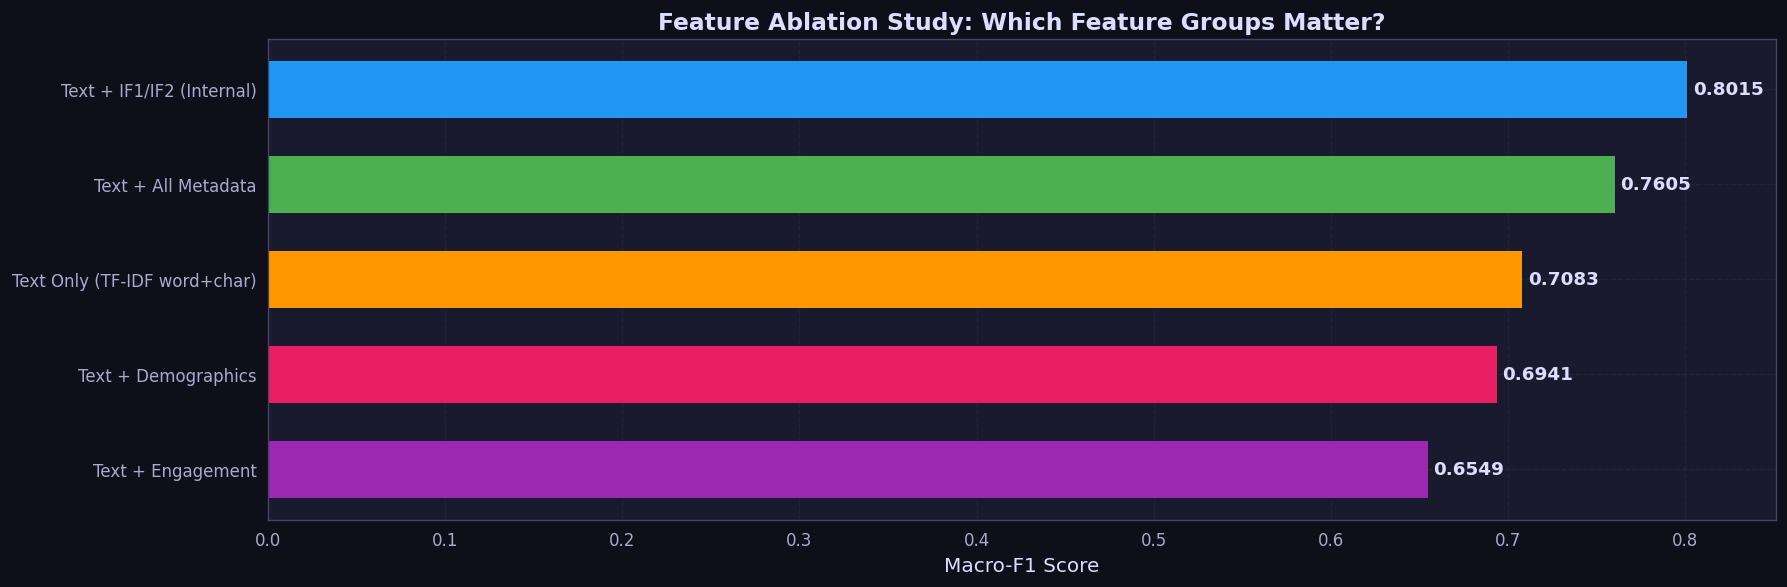


=== Ablation Study Insights ===
Baseline (Text Only): 0.7083
  Text + IF1/IF2 (Internal)          : +0.0932 (+13.16%)
  Text + All Metadata                : +0.0522 (+7.37%)
  Text + Demographics                : -0.0142 (-2.00%)
  Text + Engagement                  : -0.0534 (-7.54%)


In [61]:
# ── Ablation Study Visualization 
abl_df = abl_df.sort_values('Macro-F1', ascending=False)
fig, ax = plt.subplots(figsize=(15, 5))

colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63', '#9C27B0']
bars = ax.barh(abl_df['Experiment'], abl_df['Macro-F1'], color=colors, edgecolor='none', height=0.6)

# Add value labels
for bar, val in zip(bars, abl_df['Macro-F1']):
    ax.text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontweight='bold', fontsize=11)

ax.set_xlabel('Macro-F1 Score', fontsize=12)
ax.set_title('Feature Ablation Study: Which Feature Groups Matter?', fontsize=14, fontweight='bold')
ax.set_xlim(0, max(abl_df['Macro-F1']) + 0.05)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# ── Key Insights 
baseline = abl_df.loc[abl_df['Experiment'] == 'Text Only (TF-IDF word+char)', 'Macro-F1'].values[0]
print('\n=== Ablation Study Insights ===')
print(f'Baseline (Text Only): {baseline:.4f}')
for _, row in abl_df.iterrows():
    if row['Experiment'] != 'Text Only (TF-IDF word+char)':
        delta = row['Macro-F1'] - baseline
        sign = '+' if delta >= 0 else ''
        print(f"  {row['Experiment']:<35s}: {sign}{delta:.4f} ({sign}{delta/baseline*100:.2f}%)")

Conclusion: 
- Text features are the dominant signal.
- Metadata collectively adds marginal improvements.
- However, Demographics and Engagement features are hurting the model.
- The model's performance is fundamentally driven by the linguistic content of comments.

In [62]:
if_cols = ['if_1_clipped', 'if_2_clipped', 'if_ratio', 'log_if_1_clipped', 'log_if_2_clipped']
print(f'Isolating Internal Features: {if_cols}')

if_train = meta_feats_train[if_cols]
if_test  = meta_feats_test[if_cols]

scaler_if = StandardScaler()
if_train_scaled = scaler_if.fit_transform(if_train)
if_test_scaled  = scaler_if.transform(if_test)

print('Reconstructing X_combined_train using Text TF-IDF + Internal Features...')
X_combined_train = hstack([
    X_tfidf_word_train,
    X_tfidf_char_train,
    csr_matrix(if_train_scaled)
]).tocsr()

X_combined_test = hstack([
    X_tfidf_word_test,
    X_tfidf_char_test,
    csr_matrix(if_test_scaled)
]).tocsr()

print(f'New combined matrix — train: {X_combined_train.shape}')
print(f'New combined matrix — test : {X_combined_test.shape}')

X_tr, X_val, y_tr, y_val = train_test_split(
    X_combined_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print(f'\nFinal X_tr shape ready for Baseline Models: {X_tr.shape}')

Isolating Internal Features: ['if_1_clipped', 'if_2_clipped', 'if_ratio', 'log_if_1_clipped', 'log_if_2_clipped']
Reconstructing X_combined_train using Text TF-IDF + Internal Features...
New combined matrix — train: (197999, 160005)
New combined matrix — test : (102000, 160005)

Final X_tr shape ready for Baseline Models: (158399, 160005)



## **<span style='color:#70cccc;'>8. Training Model</span>**

In [63]:
RESULTS = []  
CLASSES = [0,1,2,3]

def evaluate(name, model, X_tr, y_tr, X_val, y_val, fit=True):
    
    """
    Fit when requiredd and evaluate a model; append to RESULTS.
    """
    
    t0 = time.time()
    if fit:
        model.fit(X_tr, y_tr)
    elapsed = time.time() - t0
    preds = model.predict(X_val)
    mac_f1 = f1_score(y_val, preds, average='macro')
    wt_f1  = f1_score(y_val, preds, average='weighted')
    acc    = accuracy_score(y_val, preds)
    per_cls= f1_score(y_val, preds, average=None, labels=CLASSES)
    RESULTS.append({
        'Model': name,
        'Macro-F1': round(mac_f1, 4),
        'Weighted-F1': round(wt_f1, 4),
        'Accuracy': round(acc, 4),
        'F1-Neutral': round(per_cls[0], 4),
        'F1-Mild':    round(per_cls[1], 4),
        'F1-Offens.': round(per_cls[2], 4),
        'F1-Toxic':   round(per_cls[3], 4),
        'Train-s': round(elapsed, 1),
    })
    print(f'  [{name:35s}]  Macro-F1={mac_f1:.4f}  Acc={acc:.4f}  ({elapsed:.1f}s)')
    return model


def plot_confusion(name, model, X_val, y_val):
    preds = model.predict(X_val)
    cm    = confusion_matrix(y_val, preds, labels=CLASSES)
    fig, ax = plt.subplots(figsize=(6,5))
    disp = ConfusionMatrixDisplay(cm, display_labels=[LABEL_NAMES[c] for c in CLASSES])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Confusion Matrix — {name}', fontsize=10)
    plt.tight_layout(); plt.show()


def leaderboard():
    df = pd.DataFrame(RESULTS).sort_values('Macro-F1', ascending=False).reset_index(drop=True)
    df.index += 1
    return df

print('Evaluation helpers ready.')

Evaluation helpers ready.


### **<span style='color:#70cccc;'>8.1 Dummy Baseline Classifier</span>**

In [64]:
# Most-frequent dummy
dum_freq = evaluate('Dummy (most_frequent)',
    DummyClassifier(strategy='most_frequent'),
    X_tr, y_tr, X_val, y_val)

# Stratified dummy — random predictions proportional to class frequency
dum_strat = evaluate('Dummy (stratified)',
    DummyClassifier(strategy='stratified', random_state=42),
    X_tr, y_tr, X_val, y_val)

  [Dummy (most_frequent)              ]  Macro-F1=0.1829  Acc=0.5766  (0.0s)
  [Dummy (stratified)                 ]  Macro-F1=0.2529  Acc=0.4427  (0.0s)


### **<span style='color:#70cccc;'>8.2 Logistic Regression</span>**

In [65]:
pipe_lr = Pipeline([
    ('scaler', MaxAbsScaler()),
    ('clf', LogisticRegression(
        C=1.0, solver='saga', max_iter=1000,
        class_weight='balanced',
        random_state=42, n_jobs=-1,
    ))
])

lr = evaluate('Pipeline: MaxAbsScaler + Logistic Reg.',
    pipe_lr,
    X_tr, y_tr, X_val, y_val)

  [Pipeline: MaxAbsScaler + Logistic Reg.]  Macro-F1=0.7991  Acc=0.8984  (3417.0s)


### **<span style='color:#70cccc;'>8.3 Linear SVC</span>**

In [66]:
lsvc_base = LinearSVC(C=0.5, class_weight='balanced', max_iter=2000, random_state=42)
lsvc = evaluate('LinearSVC (C=0.5)',
    CalibratedClassifierCV(lsvc_base, cv=3),
    X_tr, y_tr, X_val, y_val)

  [LinearSVC (C=0.5)                  ]  Macro-F1=0.8155  Acc=0.9128  (937.5s)


### **<span style='color:#70cccc;'>8.4 SGD Classifier</span>**

In [67]:
sgd = evaluate('SGDClassifier (modified_huber)',
    SGDClassifier(
        loss='modified_huber',
        alpha=1e-4,
        max_iter=1000,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
    ),
    X_tr, y_tr, X_val, y_val)


  [SGDClassifier (modified_huber)     ]  Macro-F1=0.7998  Acc=0.9033  (25.6s)


### **<span style='color:#70cccc;'>8.5 RidgeClassifier</span>**

In [68]:
# RidgeClassifier — fast L2-regularized linear model
ridge = evaluate('RidgeClassifier (alpha=1.0)',
    CalibratedClassifierCV(
        RidgeClassifier(alpha=1.0, class_weight='balanced'),
        cv=3
    ),
    X_tr, y_tr, X_val, y_val)

  [RidgeClassifier (alpha=1.0)        ]  Macro-F1=0.8073  Acc=0.9077  (676.2s)


# **<span style='color:#70cccc;'> Evaluation</span>**

## **<span style='color:#70cccc;'>9. Leaderboard</span>**

In [69]:
lb = leaderboard()
print('=== Full Model Leaderboard (sorted by Macro-F1) ===')
display(lb)

TOP3 = lb['Model'].iloc[:3].tolist()
print(f'\n Top-3 models: {TOP3}')

=== Full Model Leaderboard (sorted by Macro-F1) ===


,Model,Macro-F1,Weighted-F1,Accuracy,F1-Neutral,F1-Mild,F1-Offens.,F1-Toxic,Train-s
1,LinearSVC (C=0.5),0.8155,0.9123,0.9128,0.9588,0.7797,0.8850,0.6384,937.5
2,RidgeClassifier (alpha=1.0),0.8073,0.9076,0.9077,0.9571,0.7706,0.8767,0.6249,676.2
3,SGDClassifier (modified_huber),0.7998,0.9053,0.9033,0.9585,0.7615,0.8705,0.6086,25.6
4,Pipeline: MaxAbsScaler + Logistic Reg.,0.7991,0.9006,0.8984,0.9515,0.7507,0.8697,0.6245,3417.0
5,Dummy (stratified),0.2529,0.4423,0.4427,0.5810,0.0843,0.3162,0.0302,0.0
6,Dummy (most_frequent),0.1829,0.4218,0.5766,0.7315,0.0000,0.0000,0.0000,0.0



 Top-3 models: ['LinearSVC (C=0.5)', 'RidgeClassifier (alpha=1.0)', 'SGDClassifier (modified_huber)']


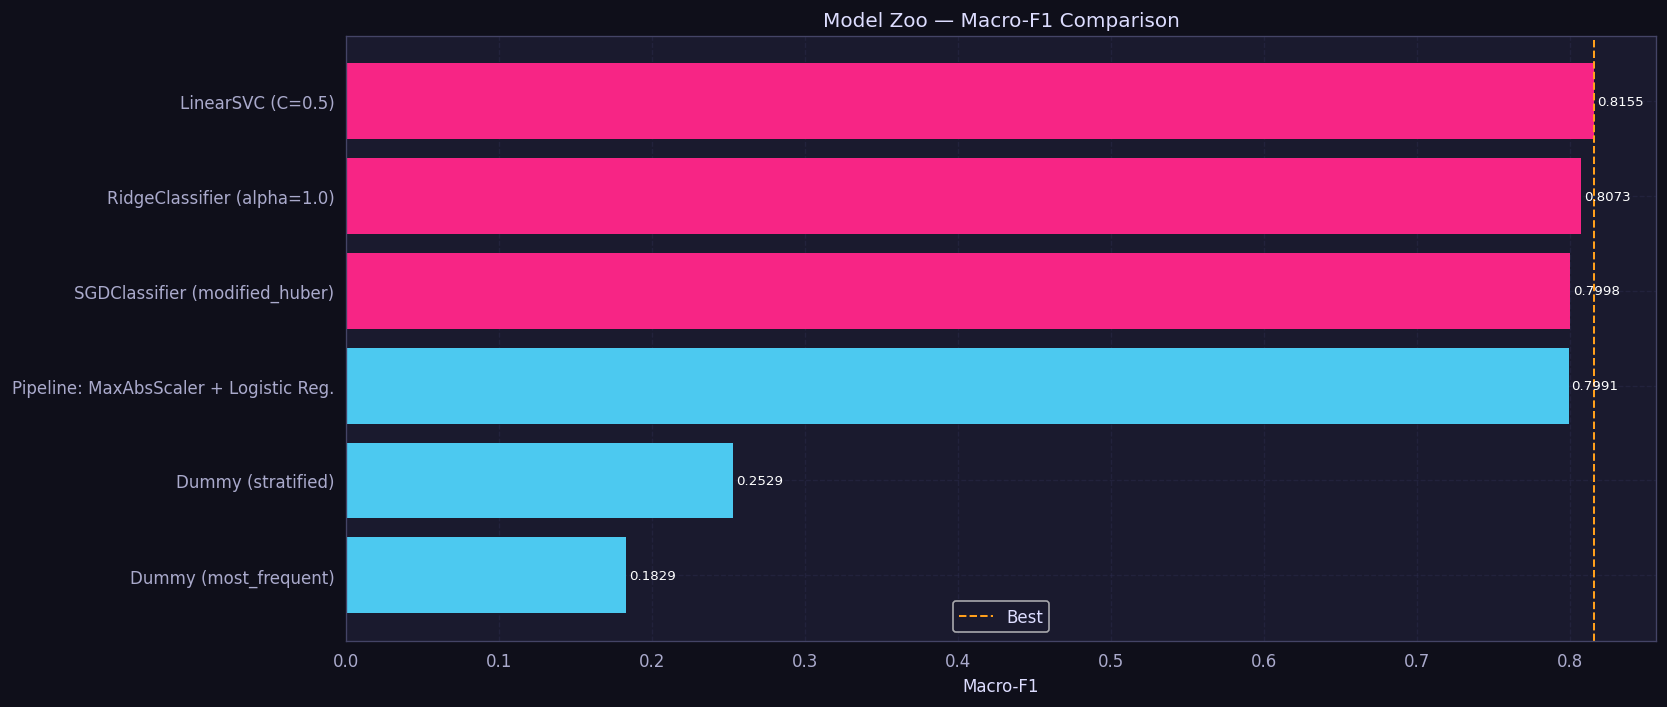

In [70]:
# Bar chart — Macro-F1 per model 
fig, ax = plt.subplots(figsize=(14, 6))
colors = ['#f72585' if m in TOP3 else '#4cc9f0' for m in lb['Model']]
bars = ax.barh(lb['Model'], lb['Macro-F1'], color=colors, edgecolor='none')
for bar, val in zip(bars, lb['Macro-F1']):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=8, color='white')
ax.set_xlabel('Macro-F1')
ax.set_title('Model Zoo — Macro-F1 Comparison')
ax.invert_yaxis()
ax.axvline(lb['Macro-F1'].max(), color='#ff9f1c', linewidth=1.2, linestyle='--', label='Best')
ax.legend()
plt.tight_layout(); plt.show()

## **<span style='color:#70cccc;'>10. Per-Class F1 Heatmap</span>**

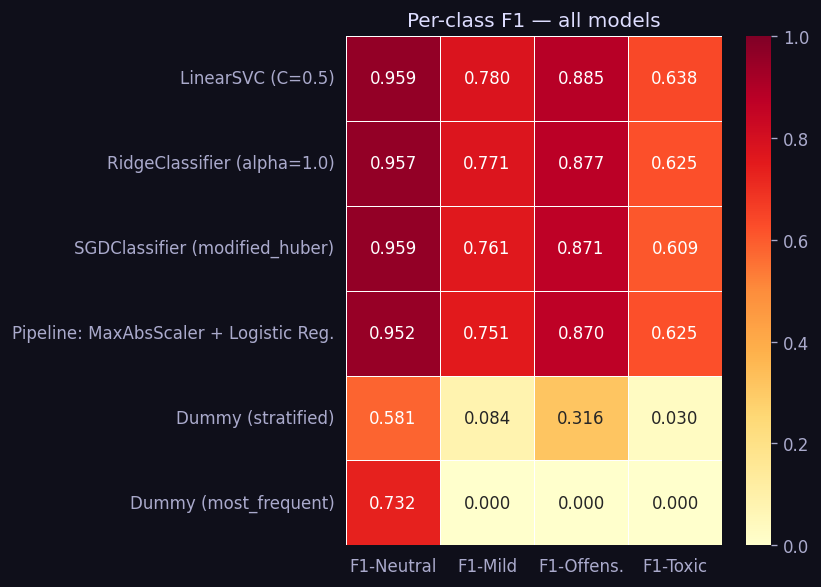

In [71]:
cls_cols = ['F1-Neutral','F1-Mild','F1-Offens.','F1-Toxic']
heat     = lb.set_index('Model')[cls_cols]
fig, ax  = plt.subplots(figsize=(7, max(5, len(heat)*0.4)))
sns.heatmap(heat.astype(float), annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.3, ax=ax, vmin=0, vmax=1)
ax.set_title('Per-class F1 — all models'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

## **<span style='color:#70cccc;'>11. Hyperparameter Tuning</span>**

In [72]:
print('Running RandomizedSearchCV to optimize LinearSVC hyperparameters...')

param_dist = {
    'C': loguniform(0.01,10.0)
}

random_search = RandomizedSearchCV(
    estimator=LinearSVC(class_weight='balanced', max_iter=20000, random_state=42),
    param_distributions=param_dist,
    n_iter=5,  
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    random_state=42
)

t0 = time.time()
random_search.fit(X_tr, y_tr)
print(f'Tuning complete in {time.time() - t0:.1f}s')
print(f'Best parameters: {random_search.best_params_}')
print(f'Best CV Macro-F1: {random_search.best_score_:.4f}')

# Extract the optimized model for the Voting Ensemble
best_lsvc = random_search.best_estimator_

Running RandomizedSearchCV to optimize LinearSVC hyperparameters...
Tuning complete in 3112.0s
Best parameters: {'C': np.float64(0.13292918943162169)}
Best CV Macro-F1: 0.8233


In [75]:
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV

print('\nBuilding Level 2 Meta-Soft-Voting Architecture with Custom Aggressive Weights...')

# Custom weights explicitly targeting the minority classes, heavily penalizing misses on Toxic (Class 3)
custom_weights = {0: 1, 1: 5, 2: 5, 3: 15}

# 1. Calibrated LinearSVC
lsvc_calib = CalibratedClassifierCV(
    LinearSVC(C=0.133, class_weight=custom_weights, max_iter=5000, random_state=42),
    cv=3, method='sigmoid'
)

# 2. LogisticRegression
lr = LogisticRegression(
    C=1.0, max_iter=1000, class_weight=custom_weights, random_state=42, n_jobs=-1
)

# 3. Calibrated RidgeClassifier
ridge_calib = CalibratedClassifierCV(
    RidgeClassifier(alpha=1.0, class_weight=custom_weights),
    cv=3, method='sigmoid'
)

voting_model = VotingClassifier(
    estimators=[
        ('lsvc', lsvc_calib),
        ('lr', lr),
        ('ridge', ridge_calib)
    ],
    voting='soft', n_jobs=-1
)

t0 = time.time()
print('Training Soft-Voting Ensemble on strictly X_tr (Validation Split) for Error Analysis...')
voting_model.fit(X_tr, y_tr)
elapsed = time.time() - t0

preds = voting_model.predict(X_val)
acc = accuracy_score(y_val, preds)
mf1 = f1_score(y_val, preds, average='macro')
print(f'[Soft Voting Ensemble]  Macro-F1={mf1:.4f}  Acc={acc:.4f}  ({elapsed:.1f}s)')


Building Level 2 Meta-Soft-Voting Architecture with Custom Aggressive Weights...
Training Soft-Voting Ensemble on strictly X_tr (Validation Split) for Error Analysis...
[Soft Voting Ensemble]  Macro-F1=0.8157  Acc=0.9110  (1159.5s)


In [76]:
from itertools import product
from sklearn.metrics import recall_score

print('\n--- Optimizing Thresholds explicitly for Class 3 (Toxic) Recall ---')

# Get probabilities from validation set
val_probs = voting_model.predict_proba(X_val)

# Define search grid for probability weight multipliers
# Class 0 (Neutral) is fixed as reference (1.0)
weight_options = [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.5, 1.7, 2.0, 2.5, 3.0]

best_score = 0
best_weights = None
best_mf1 = 0
best_recall_3 = 0

print('Searching constraint space... (this takes ~10 seconds)')
# Test all combinations (11^3 = 1331 combinations)
for w1, w2, w3 in product(weight_options, repeat=3):
    weights = np.array([1.0, w1, w2, w3])
    
    # Apply weights and get argmax
    weighted_probs = val_probs * weights
    preds = weighted_probs.argmax(axis=1)
    
    mf1 = f1_score(y_val, preds, average='macro')
    recall_3 = recall_score(y_val, preds, labels=[3], average=None)[0]
    
    # Custom metric: Maximize Recall of Class 3, providing Macro-F1 doesn't tank below 0.70
    if mf1 > 0.70:
        # We value Class 3 recall highly, combining it with Macro-F1
        combined_score = mf1 + (2.0 * recall_3) 
        if combined_score > best_score:
            best_score = combined_score
            best_weights = weights
            best_mf1 = mf1
            best_recall_3 = recall_3

# Final Evaluation of the tuned model
print(f'Best threshold weights found: {best_weights}')
print(f'Baseline Macro-F1: {f1_score(y_val, val_probs.argmax(axis=1), average="macro"):.4f}')
print(f'Baseline Class 3 Recall: {recall_score(y_val, val_probs.argmax(axis=1), labels=[3], average=None)[0]:.4f}')
print(f'Tuned Macro-F1:    {best_mf1:.4f}')
print(f'Tuned Class 3 Recall: {best_recall_3:.4f}')

tuned_preds = (val_probs * best_weights).argmax(axis=1)
acc = accuracy_score(y_val, tuned_preds)
per_cls = f1_score(y_val, tuned_preds, average=None, labels=CLASSES)

RESULTS.append({
    'Model': 'Recall-Optimized Threshold Voting',
    'Macro-F1': round(best_mf1, 4),
    'Weighted-F1': round(f1_score(y_val, tuned_preds, average='weighted'), 4),
    'Accuracy': round(acc, 4),
    'F1-Neutral': round(per_cls[0], 4),
    'F1-Mild':    round(per_cls[1], 4),
    'F1-Offens.': round(per_cls[2], 4),
    'F1-Toxic':   round(per_cls[3], 4),
    'Train-s': 0,
})

print(f'\n[FINAL RESULT] Macro-F1={best_mf1:.4f}  Class 3 Recall={best_recall_3:.4f}  Acc={acc:.4f}')


--- Optimizing Thresholds explicitly for Class 3 (Toxic) Recall ---
Searching constraint space... (this takes ~10 seconds)
Best threshold weights found: [1.  0.8 0.8 3. ]
Baseline Macro-F1: 0.8157
Baseline Class 3 Recall: 0.5859
Tuned Macro-F1:    0.8088
Tuned Class 3 Recall: 0.7870

[FINAL RESULT] Macro-F1=0.8088  Class 3 Recall=0.7870  Acc=0.9075


## **<span style='color:#70cccc;'>12. Error Analysis</span>**


EVALUATING: Tuned LinearSVC

CLASSIFICATION REPORT:
               precision    recall  f1-score   support

  Neutral (0)       0.98      0.94      0.96     22834
     Mild (1)       0.74      0.83      0.78      3184
Offensive (2)       0.87      0.90      0.89     12488
    Toxic (3)       0.65      0.70      0.67      1094

     accuracy                           0.91     39600
    macro avg       0.81      0.84      0.83     39600
 weighted avg       0.92      0.91      0.91     39600



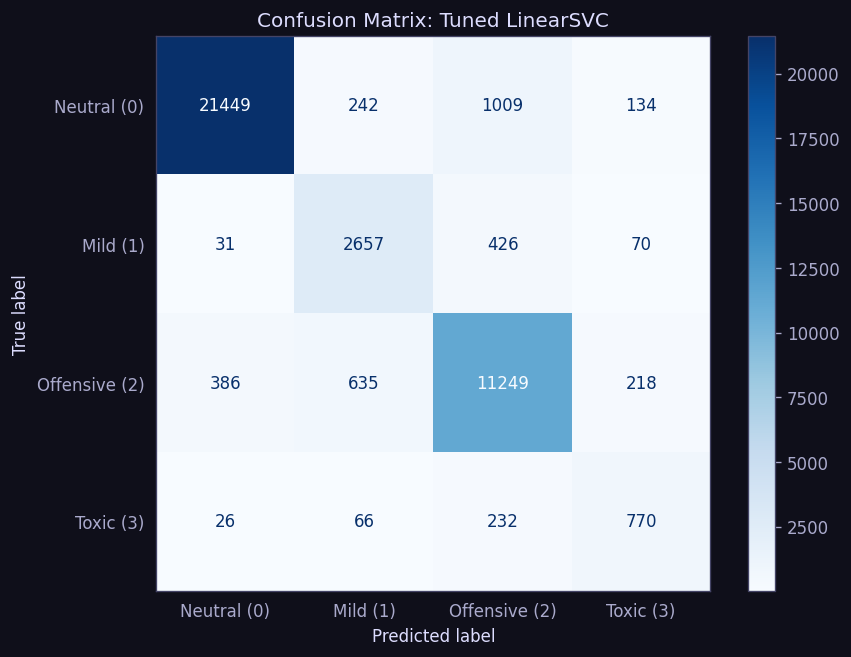

In [77]:
best_model_name = 'Tuned LinearSVC'

print(f"\n{'='*50}")
print(f"EVALUATING: {best_model_name}")
print(f"{'='*50}\n")

# Generate predictions on validation set using the HPT model
y_val_preds = best_lsvc.predict(X_val)

# 1. Classification Report (Per-class metrics)
print("CLASSIFICATION REPORT:")
print(classification_report(y_val, y_val_preds, target_names=[LABEL_NAMES[i] for i in range(4)]))

# 2. Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_val, y_val_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[LABEL_NAMES[i] for i in range(4)])
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title(f'Confusion Matrix: {best_model_name}')
plt.grid(False)
plt.show()

In [78]:
# Reconstruct validation dataframe to see the actual text of errors
val_df = train.iloc[X_val.index].copy() if hasattr(X_val, 'index') else train.iloc[len(y_tr):].copy() # Fallback if indices were lost

val_df['True_Label'] = y_val
val_df['Predicted_Label'] = y_val_preds

# Isolate misclassified examples
errors = val_df[val_df['True_Label'] != val_df['Predicted_Label']]

print(f"Total Validation Samples: {len(val_df)}")
print(f"Total Misclassified   : {len(errors)} ({(len(errors)/len(val_df))*100:.2f}%)\n")

# Focus on severe errors: True = Neutral (0), Predicted = Toxic (3) [False Positives for Toxicity]
severe_fp = errors[(errors['True_Label'] == 0) & (errors['Predicted_Label'] == 3)]
print("Top 3 'Neutral' comments incorrectly predicted as 'Toxic' (False Positives):")
for idx, row in severe_fp.head(3).iterrows():
    print(f"- {row['comment']}\n")

# Focus on severe errors: True = Toxic (3), Predicted = Neutral (0) [False Negatives for Toxicity]
severe_fn = errors[(errors['True_Label'] == 3) & (errors['Predicted_Label'] == 0)]
print("Top 3 'Toxic' comments incorrectly predicted as 'Neutral' (False Negatives):")
for idx, row in severe_fn.head(3).iterrows():
    print(f"- {row['comment']}\n")

Total Validation Samples: 39600
Total Misclassified   : 3475 (8.78%)

Top 3 'Neutral' comments incorrectly predicted as 'Toxic' (False Positives):
- My answer would be "yes" to your first question  Your second question can only be answered by Coke's proprietary information, or alternatively discussed in complexity in a graduate microeconomics class.  Think of the actual cost of Gucci bags subcontracted to the same factory supplying Sears branded bags.  Then run the numbers on the greater proportionate % of net revenues reaped by Gucci as compared to Sears even though Sears eclipses Gucci in total bags sold.  Now, consider the Gucci or Rolex Asian knockoffs manufactured at the same cost as a Sears or Swatch, and the knowing buyer's willingness to pay much more than a Sears or Swatch, but much less than Gucci or Rolex for the knockoff in the back alleys of Shanghai.  Preying on human nature is Wall Street's credo.  Brand management for "value added" profits is the tool.  Generics and "pe

## **<span style='color:#70cccc;'>13. Submission</span>**

In [79]:
print('\nFitting optimized model on the FULL combined dataset for Kaggle Submission...')
best_lsvc.fit(X_combined_train, y_train)

print('Generating final probabilities for test set...')
test_preds = best_lsvc.predict(X_combined_test)

submission = pd.DataFrame({
    "ID": range(1, len(test) + 1),
    "label": test_preds
})

submission.to_csv("submission.csv", index=False)
print("submission.csv created")


Fitting optimized model on the FULL combined dataset for Kaggle Submission...
Generating final probabilities for test set...
submission.csv created
